# QPM Final Project: Multi-Strategy Alpha & Portfolio Construction

## Overview
Six alpha signals combined via:
- **Method A**: Max-Sharpe weight optimisation (IS/OOS train-test split)
- **Method B**: Ridge walk-forward ML (always OOS by construction)

## Position Management (仓位管理)
- **High EPU** (top 10%): scale positions to **×0.5** — reduce exposure during uncertainty spikes
- **Low EPU** (bottom 10%): scale positions to **×2.0** — amplify during calm markets  
- **Normal**: ×1.0

## Portfolio: Long top 10%, Short bottom 10% on combined signal


In [1]:
"""
============================================================
QPM Final Project: Multi-Strategy Alpha & Portfolio Construction
============================================================
NOTE: When running as a standalone .py script, set non-interactive backend:
  MPLBACKEND=Agg python qpm_final_project.py
In Jupyter notebooks, the default interactive backend is fine.


Six strategies:
  1. Cross-Sectional Echo (Intermediate-Term Momentum)
  2. Profitability × Underreaction
  3. Profitability Improvement Filter
  4. Investment (CMA) × Overinvestment Correction
  5. Volume Percentile Factor
  6. Volume × Risk Management (Fear-Based)

Signal combination:
  Method A: Max-Sharpe weight optimization
  Method B: Ridge/ElasticNet walk-forward ML

Portfolio: Long top 10%, Short bottom 10% on combined signal
Analytics : Cumulative returns, factor regressions, IR tables
"""

'\n============================================================\nQPM Final Project: Multi-Strategy Alpha & Portfolio Construction\n============================================================\nNOTE: When running as a standalone .py script, set non-interactive backend:\n  MPLBACKEND=Agg python qpm_final_project.py\nIn Jupyter notebooks, the default interactive backend is fine.\n\n\nSix strategies:\n  1. Cross-Sectional Echo (Intermediate-Term Momentum)\n  2. Profitability × Underreaction\n  3. Profitability Improvement Filter\n  4. Investment (CMA) × Overinvestment Correction\n  5. Volume Percentile Factor\n  6. Volume × Risk Management (Fear-Based)\n\nSignal combination:\n  Method A: Max-Sharpe weight optimization\n  Method B: Ridge/ElasticNet walk-forward ML\n\nPortfolio: Long top 10%, Short bottom 10% on combined signal\nAnalytics : Cumulative returns, factor regressions, IR tables\n'

## 0. Imports & Style

In [2]:
%matplotlib inline
# ============================================================
# 0. IMPORTS & STYLE
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import warnings
import os
import sys

warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=RuntimeWarning)

from cycler import cycler
from matplotlib import rcParams
from scipy.optimize import minimize
from scipy.stats import rankdata
from sklearn.linear_model import RidgeCV, ElasticNetCV
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from statsmodels.iolib.summary2 import summary_col

### Matplotlib style (matching qpm.py)

In [3]:
rcParams['font.serif']          = ['Bitstream Vera Sans']
rcParams['figure.figsize']      = (14, 5)
rcParams['font.size']           = 13
rcParams['grid.linewidth']      = 0.3
rcParams['grid.color']          = '0.7'
rcParams['axes.prop_cycle']     = (
    cycler('color',     ['maroon', 'steelblue', 'darkorange', 'green', 'purple', 'gray']) +
    cycler('linestyle', ['-', '--', ':', '-.', '-', '--'])
)
rcParams['axes.grid']           = True
rcParams['axes.grid.axis']      = 'y'
rcParams['axes.spines.right']   = False
rcParams['axes.spines.top']     = False
rcParams['legend.frameon']      = False

DataFrame = pd.DataFrame
Series    = pd.Series
pd.options.mode.chained_assignment = None

In [4]:
# ============================================================
# 1. CONFIGURATION
# ============================================================
DATA_DIR        = '.'           # MasterData.parquet lives here
FILE_NAME       = 'MasterData.parquet'
SAMPLE_START    = '2003-01-01'  # leave 12 months for momentum warm-up
SAMPLE_END      = '2025-08-01'
REMOVE_MICROCAP = False
NUM_PORT        = 10            # decile sort → long P10, short P1
TRAIN_WINDOW    = 60            # months for walk-forward ML (Method B)

### Train / Test split (for Method A OOS evaluation)

In [5]:
# Method A weights are estimated on TRAIN period only,
# then applied UNCHANGED to TEST period → true out-of-sample.
# Method B is already walk-forward (always OOS by construction).
TRAIN_END  = '2013-12-31'   # ~10-year training window
TEST_START = '2014-01-01'   # ~11-year out-of-sample evaluation window

SIGNAL_NAMES = [
    'signal_1_mom',
    'signal_2_prof',
    'signal_3_profchg',
    'signal_4_inv',
    'signal_5_volpct',
    'signal_6_fear',
]
SIGNAL_LABELS = [
    'S1: Momentum',
    'S2: Profitability',
    'S3: Prof. Improvement',
    'S4: Investment',
    'S5: Vol Percentile',
    'S6: Fear-Scaled Mom',
]

print("Configuration loaded.")
print(f"  Sample: {SAMPLE_START}  →  {SAMPLE_END}")
print(f"  Num portfolios: {NUM_PORT}  |  ML train window: {TRAIN_WINDOW} months")

Configuration loaded.
  Sample: 2003-01-01  →  2025-08-01
  Num portfolios: 10  |  ML train window: 60 months


## Section 1: Load & Prepare Data

In [6]:
# ============================================================
# SECTION 1 : LOAD & PREPARE DATA
# ============================================================

print("\n" + "="*60)
print("SECTION 1 : LOAD DATA")
print("="*60)


SECTION 1 : LOAD DATA


### 1.1 Load raw parquet

In [7]:
print("> Loading MasterData.parquet …")
df_raw = pd.read_parquet(os.path.join(DATA_DIR, FILE_NAME))

# Ensure ldate is datetime
df_raw['ldate'] = pd.to_datetime(df_raw['ldate'])

# Drop duplicates
df_raw.drop_duplicates(subset=['permno', 'ldate'], keep='first', inplace=True)
df_raw.sort_values(['permno', 'ldate'], inplace=True)
df_raw.reset_index(drop=True, inplace=True)

print(f"  Loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} cols")
print(f"  Date range: {df_raw['ldate'].min().date()} → {df_raw['ldate'].max().date()}")
print(f"  Unique stocks: {df_raw['permno'].nunique():,}")

> Loading MasterData.parquet …


  Loaded: 1,181,207 rows × 177 cols
  Date range: 2001-07-01 → 2025-08-01
  Unique stocks: 11,669


### 1.2 Auxiliary variables (matching qpm.load_data logic)

In [8]:
print("> Creating auxiliary variables …")

# 1-month lag for continuity screening
df_raw['ldate_lag1']  = df_raw.groupby('permno')['ldate'].shift(1)
df_raw['screen1']     = (df_raw['ldate_lag1'] == df_raw['ldate'] - pd.DateOffset(months=1)).astype(float)
df_raw['screen1']     = df_raw['screen1'].replace(0, np.nan)

# 12-month lag for continuity screening
df_raw['ldate_lag12'] = df_raw.groupby('permno')['ldate'].shift(12)
df_raw['screen12']    = (df_raw['ldate_lag12'] == df_raw['ldate'] - pd.DateOffset(months=12)).astype(float)
df_raw['screen12']    = df_raw['screen12'].replace(0, np.nan)

# Lagged market cap (for VW portfolios)
df_raw['me_lagged'] = df_raw.groupby('permno')['me'].shift(1) * df_raw['screen1']

# Rename returns column to match qpm convention
if 'daret' not in df_raw.columns:
    df_raw['daret'] = df_raw['ret']

# Profitability level (already in data; re-create for safety)
df_raw['profitA'] = (df_raw['revt'] - df_raw['cogs']) / df_raw['at'].replace(0, np.nan)

# Save FF factors for analyze_strategy compatibility
ff_cols = ['ldate', 'rf', 'mktrf', 'smb', 'hml', 'umd', 'rmw', 'cma']
df_raw[ff_cols].drop_duplicates().to_parquet('FFData.parquet')
print("  Saved FFData.parquet for factor regressions.")

> Creating auxiliary variables …
  Saved FFData.parquet for factor regressions.


### 1.3 Quick summary

In [9]:
print("\n> Key variable non-NaN counts (full panel):")
for col in ['daret', 'me', 'me_lagged', 'at', 'revt', 'cogs', 'profitA', 'vol', 'rmw']:
    n = df_raw[col].notna().sum()
    print(f"  {col:>12}: {n:>10,}")


> Key variable non-NaN counts (full panel):
         daret:  1,181,040
            me:  1,181,048
     me_lagged:  1,168,814
            at:  1,181,207
          revt:  1,181,207
          cogs:  1,181,207
       profitA:  1,181,195
           vol:  1,181,048
           rmw:  1,181,207


### 1.4 Visualization: coverage over time

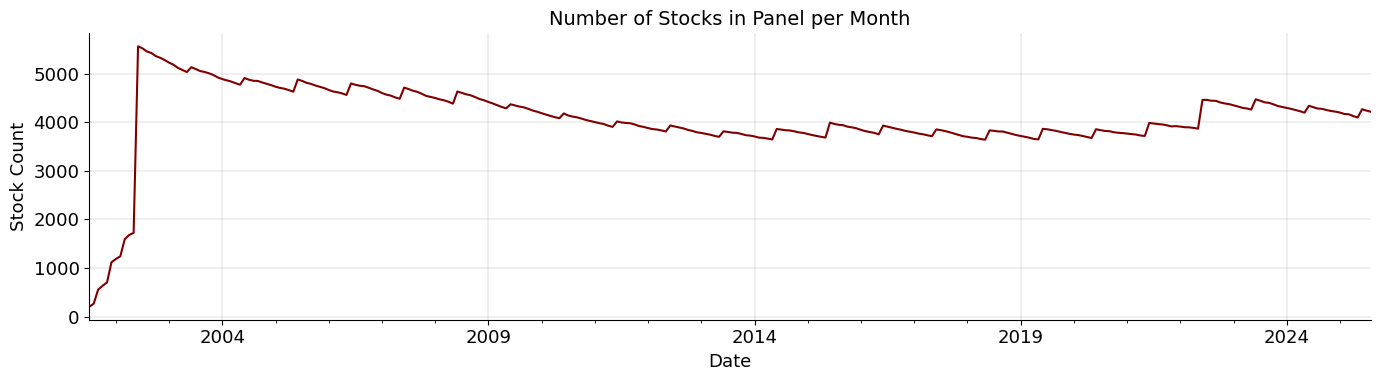

In [10]:
coverage = df_raw.groupby('ldate')['permno'].count()
fig, ax = plt.subplots(figsize=(14, 4))
coverage.plot(ax=ax, color='maroon', lw=1.5)
ax.set_title("Number of Stocks in Panel per Month", fontsize=14)
ax.set_xlabel("Date"); ax.set_ylabel("Stock Count")
plt.tight_layout()
plt.savefig('fig_coverage.png', dpi=120)
plt.show(); plt.close()

## Section 2: Construct Signals

In [11]:
# ============================================================
# SECTION 2 : CONSTRUCT SIGNALS
# ============================================================

print("\n" + "="*60)
print("SECTION 2 : CONSTRUCT SIGNALS")
print("="*60)

df = df_raw.copy()
df.sort_values(['permno', 'ldate'], inplace=True)
df.reset_index(drop=True, inplace=True)

# --------------------------------------------------------
# Helper: cross-sectional z-score + winsorise
# --------------------------------------------------------
def cs_normalize(df_in, col, clip=3.0):
    """Cross-sectional z-score per month, then winsorise to ±clip."""
    df_in[col] = df_in.groupby('ldate')[col].transform(
        lambda x: (x - x.mean()) / (x.std() + 1e-8)
    ).clip(-clip, clip)
    return df_in

# --------------------------------------------------------
# Signal 1: Cross-Sectional Echo (Intermediate Momentum)
# Cumulative 6-month return from T-12 to T-7, skipping T-6 to T-1
# --------------------------------------------------------
print("\n> Signal 1: Intermediate Momentum (T-12 to T-7) …")

# 6-month rolling product of gross returns
df['_roll6m_ret'] = df.groupby('permno')['daret'].transform(
    lambda x: x.rolling(6, min_periods=4).apply(
        lambda r: np.prod(1 + r) - 1, raw=True
    )
)
# Shift by 6 so that at time t, signal = cumret ending at t-6 (i.e., t-12 to t-7)
df['signal_1_mom'] = df.groupby('permno')['_roll6m_ret'].shift(6) * df['screen12']
df = cs_normalize(df, 'signal_1_mom')
print(f"   Non-NaN: {df['signal_1_mom'].notna().sum():,}")

# --------------------------------------------------------
# Signal 2: Profitability × Underreaction
# Operating profit / Total assets (cross-sectionally ranked)
# --------------------------------------------------------
print("> Signal 2: Profitability Level …")
df['signal_2_prof'] = df['profitA'].copy()
df = cs_normalize(df, 'signal_2_prof')
print(f"   Non-NaN: {df['signal_2_prof'].notna().sum():,}")

# --------------------------------------------------------
# Signal 3: Profitability Improvement Filter
# Combines profitability LEVEL and YoY CHANGE as additive z-score composite.
# Both components are cross-sectionally normalised independently before combining,
# so neither dominates and the joint signal retains dispersion.
# --------------------------------------------------------
print("> Signal 3: Profitability Improvement …")
# YoY change in profitability (12-month lag)
df['_profitA_lag12'] = df.groupby('permno')['profitA'].shift(12) * df['screen12']
df['_delta_profitA'] = df['profitA'] - df['_profitA_lag12']

# Independently normalise level and change, then combine with 60/40 weight
# (level is the primary driver, change is the filter/enhancer)
df['_profitA_z'] = df.groupby('ldate')['profitA'].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
).clip(-3, 3)
df['_delta_profitA_z'] = df.groupby('ldate')['_delta_profitA'].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
).clip(-3, 3)

# Combined signal: rewarding high profitA AND improving profitA
# The positive delta component amplifies the signal for improving firms
df['signal_3_profchg'] = 0.6 * df['_profitA_z'] + 0.4 * df['_delta_profitA_z']
# Fill rows where delta is missing (no 12m history) with profitA signal only
mask_no_hist = df['_delta_profitA'].isna()
df.loc[mask_no_hist, 'signal_3_profchg'] = df.loc[mask_no_hist, '_profitA_z']
df = cs_normalize(df, 'signal_3_profchg')
print(f"   Non-NaN: {df['signal_3_profchg'].notna().sum():,}")

# --------------------------------------------------------
# Signal 4: Investment (CMA) × Overinvestment Correction
# Negative of total asset growth (conservative = low growth = positive signal)
# --------------------------------------------------------
print("> Signal 4: Investment / Asset Growth …")
df['_at_lag12'] = df.groupby('permno')['at'].shift(12) * df['screen12']
df['_asset_growth'] = (df['at'] - df['_at_lag12']) / df['_at_lag12'].abs().replace(0, np.nan)
# Negative: conservative investors (low asset growth) → positive signal
df['signal_4_inv'] = -df['_asset_growth']
df = cs_normalize(df, 'signal_4_inv')
print(f"   Non-NaN: {df['signal_4_inv'].notna().sum():,}")

# --------------------------------------------------------
# Signal 5: Volume Percentile Factor
# Z-score of current vol vs trailing 12-month own distribution;
# lower-than-usual volume → positive signal (negative of vol z-score)
# --------------------------------------------------------
print("> Signal 5: Volume Percentile Factor …")
df['_vol_roll_mean'] = df.groupby('permno')['vol'].transform(
    lambda x: x.rolling(12, min_periods=6).mean()
)
df['_vol_roll_std'] = df.groupby('permno')['vol'].transform(
    lambda x: x.rolling(12, min_periods=6).std()
)
df['_vol_zscore_self'] = (
    (df['vol'] - df['_vol_roll_mean']) / (df['_vol_roll_std'].replace(0, np.nan))
)
# Negative: lower than usual volume = better (less noisy/attention-driven trading)
df['signal_5_volpct'] = -df['_vol_zscore_self']
df = cs_normalize(df, 'signal_5_volpct')
print(f"   Non-NaN: {df['signal_5_volpct'].notna().sum():,}")

# --------------------------------------------------------
# Signal 6: Volume × Risk Management (Fear-Based Position Scaling)
# Scale momentum by a fear multiplier based on cross-sectional average vol stress
# --------------------------------------------------------
print("> Signal 6: Fear-Scaled Momentum …")
# Market-wide fear: cross-sectional mean of self-normalized vol z-scores
df['_mkt_fear'] = df.groupby('ldate')['_vol_zscore_self'].transform('mean')
# Normalise to [0, 1] using rolling percentile of the fear measure
df.sort_values('ldate', inplace=True)
_fear_series = df.drop_duplicates('ldate').set_index('ldate')['_mkt_fear'].sort_index()
_fear_roll = _fear_series.rolling(36, min_periods=12)
_fear_pct  = _fear_roll.apply(lambda x: (x <= x.iloc[-1]).mean(), raw=False)
_fear_pct  = _fear_pct.rename('_fear_pct')
df = df.merge(_fear_pct.reset_index().rename(columns={'_mkt_fear': '_fear_pct'}),
              on='ldate', how='left')
# Fear multiplier: scale DOWN when fear is high
df['_fear_mult'] = 1 - df['_fear_pct'].fillna(0.5)
# Signal: momentum scaled by fear dampener
df['signal_6_fear'] = df['signal_1_mom'] * df['_fear_mult']
df = cs_normalize(df, 'signal_6_fear')
df.sort_values(['permno', 'ldate'], inplace=True)
print(f"   Non-NaN: {df['signal_6_fear'].notna().sum():,}")


SECTION 2 : CONSTRUCT SIGNALS



> Signal 1: Intermediate Momentum (T-12 to T-7) …


   Non-NaN: 1,042,034
> Signal 2: Profitability Level …
   Non-NaN: 1,181,195
> Signal 3: Profitability Improvement …


   Non-NaN: 1,181,195
> Signal 4: Investment / Asset Growth …
   Non-NaN: 1,042,255
> Signal 5: Volume Percentile Factor …


   Non-NaN: 1,123,822
> Signal 6: Fear-Scaled Momentum …


   Non-NaN: 1,042,034


### 2.X: Lag each signal by 1 month (portfolio formation timing)

In [12]:
print("\n> Applying 1-month lag to all signals (portfolio formation timing) …")
for sig in SIGNAL_NAMES:
    df[sig] = df.groupby('permno')[sig].shift(1) * df['screen1']


> Applying 1-month lag to all signals (portfolio formation timing) …


### 2.Y: Summary visualization

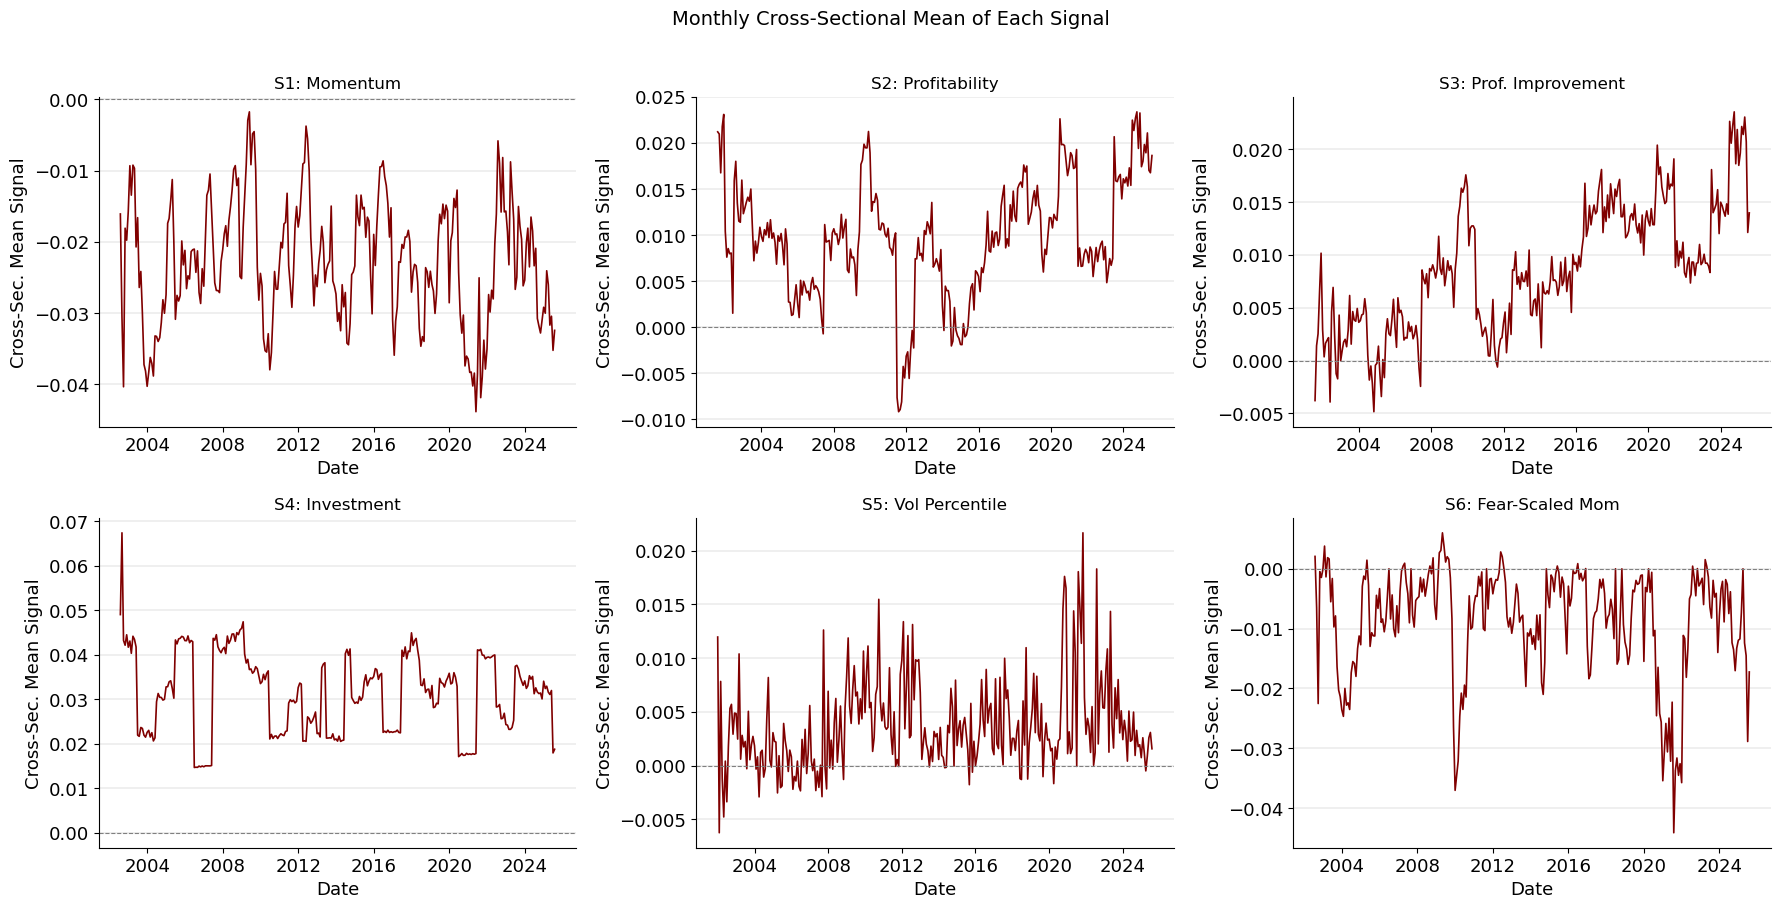


Signal Cross-Correlations:
                       S1: Momentum  S2: Profitability  S3: Prof. Improvement  \
S1: Momentum                  1.000              0.065                  0.065   
S2: Profitability             0.065              1.000                  0.926   
S3: Prof. Improvement         0.065              0.926                  1.000   
S4: Investment               -0.009              0.020                  0.063   
S5: Vol Percentile           -0.041              0.013                  0.011   
S6: Fear-Scaled Mom           0.979              0.066                  0.066   

                       S4: Investment  S5: Vol Percentile  S6: Fear-Scaled Mom  
S1: Momentum                   -0.009              -0.041                0.979  
S2: Profitability               0.020               0.013                0.066  
S3: Prof. Improvement           0.063               0.011                0.066  
S4: Investment                  1.000              -0.002               -0.009  

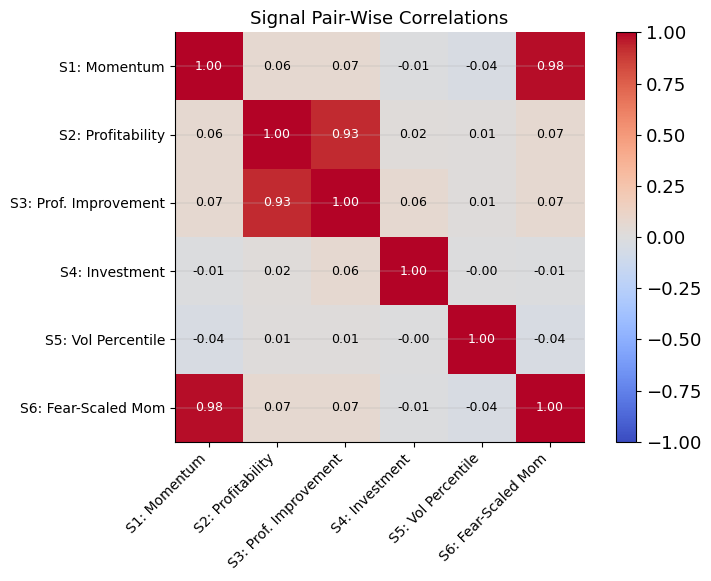

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()
for i, (sig, label) in enumerate(zip(SIGNAL_NAMES, SIGNAL_LABELS)):
    sig_ts = df.groupby('ldate')[sig].mean()
    axes[i].plot(sig_ts.index, sig_ts.values, color='maroon', lw=1.2)
    axes[i].axhline(0, color='gray', lw=0.8, linestyle='--')
    axes[i].set_title(label, fontsize=12)
    axes[i].set_xlabel('Date'); axes[i].set_ylabel('Cross-Sec. Mean Signal')
plt.suptitle("Monthly Cross-Sectional Mean of Each Signal", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_signals_ts.png', dpi=120)
plt.show(); plt.close()

# Signal correlation (using all obs)
sig_df = df[['ldate'] + SIGNAL_NAMES].dropna()
corr_matrix = sig_df[SIGNAL_NAMES].rename(
    columns=dict(zip(SIGNAL_NAMES, SIGNAL_LABELS))
).corr()
print("\nSignal Cross-Correlations:")
print(corr_matrix.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr_matrix.values, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(SIGNAL_LABELS))); ax.set_xticklabels(SIGNAL_LABELS, rotation=45, ha='right', fontsize=10)
ax.set_yticks(range(len(SIGNAL_LABELS))); ax.set_yticklabels(SIGNAL_LABELS, fontsize=10)
for ii in range(len(SIGNAL_LABELS)):
    for jj in range(len(SIGNAL_LABELS)):
        ax.text(jj, ii, f'{corr_matrix.values[ii,jj]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if abs(corr_matrix.values[ii,jj]) > 0.5 else 'black')
ax.set_title("Signal Pair-Wise Correlations", fontsize=13)
plt.tight_layout()
plt.savefig('fig_signal_corr.png', dpi=120)
plt.show(); plt.close()

## Section 3: Combine Signals (Method A & B)

In [14]:
# ============================================================
# SECTION 3 : COMBINE SIGNALS
# ============================================================

print("\n" + "="*60)
print("SECTION 3 : COMBINE SIGNALS")
print("="*60)


SECTION 3 : COMBINE SIGNALS


### 3.0: Select sample & compute individual strategy L/S returns

In [15]:
# We need these to optimize weights (Method A) and to train ML model (Method B)

# Keep only rows with at least 4 of 6 signals present (need returns for next month)
df['n_signals'] = df[SIGNAL_NAMES].notna().sum(axis=1)
df_samp = df[
    (df['ldate'] >= SAMPLE_START) &
    (df['ldate'] <= SAMPLE_END) &
    (df['daret'].notna()) &
    (df['me_lagged'].notna()) &
    (df['n_signals'] >= 3)
].copy()

print(f"  Working sample: {df_samp.shape[0]:,} obs, {df_samp['ldate'].nunique()} months, "
      f"{df_samp['permno'].nunique():,} stocks")

# Next-month return (for ML training)
df_samp['ret_next'] = df_samp.groupby('permno')['daret'].shift(-1)

  Working sample: 1,096,567 obs, 272 months, 10,855 stocks


### 3.1 Helper: compute L/S decile returns for a single signal

In [16]:
def compute_ls_returns(df_in, signal_col, num_port=10):
    """
    For each month, sort stocks into num_port portfolios by signal_col.
    Return the long-short (top minus bottom) value-weighted monthly return series.
    Uses duplicates='drop' in qcut for robustness; identifies top/bottom by
    the actual max/min portfolio labels produced.
    """
    def vw_ret(sub):
        if sub.empty or sub['me_lagged'].sum() == 0:
            return 0.0
        w = sub['me_lagged'] / sub['me_lagged'].sum()
        return (w * sub['daret']).sum()

    out = []
    for dt, grp in df_in.groupby('ldate'):
        grp = grp.dropna(subset=[signal_col, 'me_lagged', 'daret']).copy()
        if len(grp) < num_port * 3:
            continue
        try:
            grp['port'] = pd.qcut(grp[signal_col], num_port, labels=False,
                                  duplicates='drop') + 1
        except ValueError:
            continue
        p_max = grp['port'].max()
        p_min = grp['port'].min()
        if p_max == p_min:   # only one bin — skip
            continue
        top_ret = vw_ret(grp[grp['port'] == p_max])
        bot_ret = vw_ret(grp[grp['port'] == p_min])
        out.append({'ldate': dt, 'ls_ret': top_ret - bot_ret})

    if not out:
        return pd.Series(dtype=float, name='ls_ret')
    return pd.DataFrame(out).set_index('ldate')['ls_ret']


print("\n> Computing individual L/S returns for each signal …")
strat_rets = {}
for sig, label in zip(SIGNAL_NAMES, SIGNAL_LABELS):
    sub = df_samp.dropna(subset=[sig])
    strat_rets[label] = compute_ls_returns(sub, sig, NUM_PORT)
    sr = strat_rets[label]
    ann_ret = sr.mean() * 12
    ann_vol = sr.std() * np.sqrt(12)
    sharpe  = ann_ret / ann_vol if ann_vol > 0 else 0
    print(f"   {label:28s}  AnnRet={ann_ret*100:+.2f}%  AnnVol={ann_vol*100:.2f}%  Sharpe={sharpe:.3f}")

rets_df = pd.DataFrame(strat_rets).dropna(how='all')
rets_df.index = pd.to_datetime(rets_df.index)


> Computing individual L/S returns for each signal …


   S1: Momentum                  AnnRet=+7.37%  AnnVol=24.90%  Sharpe=0.296


   S2: Profitability             AnnRet=+6.90%  AnnVol=18.32%  Sharpe=0.377


   S3: Prof. Improvement         AnnRet=+3.65%  AnnVol=14.09%  Sharpe=0.259


   S4: Investment                AnnRet=+1.74%  AnnVol=14.97%  Sharpe=0.116


   S5: Vol Percentile            AnnRet=+2.20%  AnnVol=11.48%  Sharpe=0.191


   S6: Fear-Scaled Mom           AnnRet=+7.51%  AnnVol=24.42%  Sharpe=0.308


### Cumulative returns: individual strategies

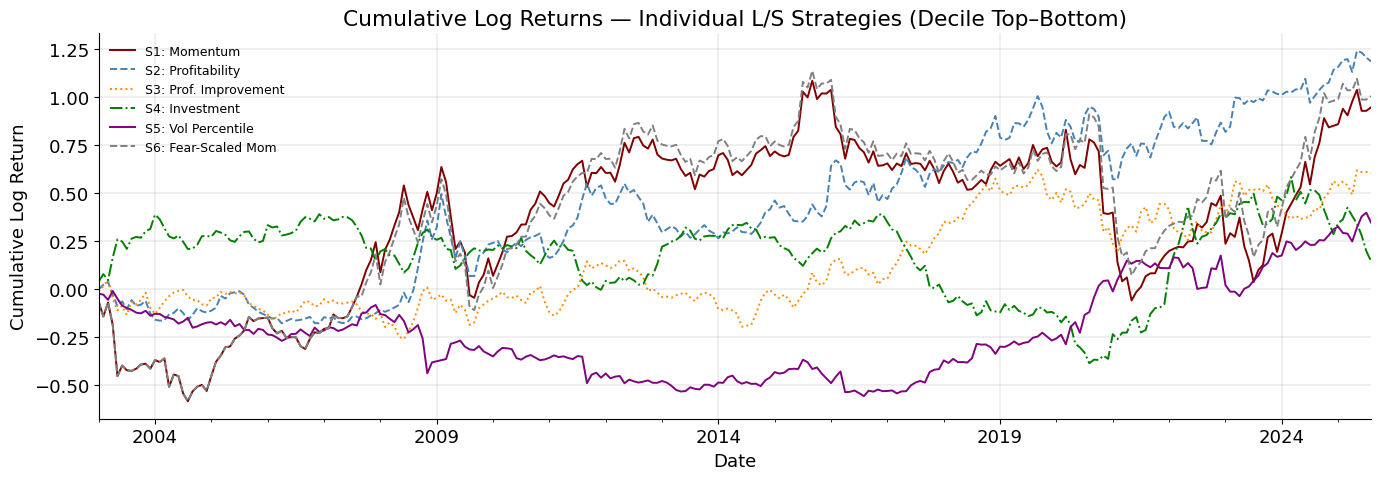

In [17]:
cum_rets = np.log(1 + rets_df.fillna(0)).cumsum()
fig, ax = plt.subplots(figsize=(14, 5))
for col in cum_rets.columns:
    cum_rets[col].plot(ax=ax, label=col, lw=1.4)
ax.set_title("Cumulative Log Returns — Individual L/S Strategies (Decile Top–Bottom)")
ax.set_xlabel("Date"); ax.set_ylabel("Cumulative Log Return")
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.savefig('fig_indiv_cumrets.png', dpi=120)
plt.show(); plt.close()

In [18]:
# ============================================================
# 3.2  METHOD A — Max-Sharpe Weight Optimization
# ============================================================

print("\n> Method A: Max-Sharpe Signal Weight Optimization …")
print(f"   Training on: {SAMPLE_START} → {TRAIN_END}  (in-sample)")
print(f"   Evaluating:  {TEST_START} → {SAMPLE_END}   (out-of-sample)")

def neg_sharpe_with_l2(weights, R, lam=0.02):
    port_ret = R @ weights
    mu  = port_ret.mean()
    vol = port_ret.std()
    sharpe = (mu / vol) if vol > 1e-9 else 0.0
    return -(sharpe - lam * np.sum(weights**2))

def build_combined_signal_A(df_in, sig_names, weights):
    """Weighted combination of signals — NaN filled with 0 (neutral)."""
    sig_mat = np.where(np.isnan(df_in[sig_names].values), 0.0, df_in[sig_names].values)
    return pd.Series(sig_mat @ weights, index=df_in.index)


> Method A: Max-Sharpe Signal Weight Optimization …
   Training on: 2003-01-01 → 2013-12-31  (in-sample)
   Evaluating:  2014-01-01 → 2025-08-01   (out-of-sample)


### Step 1: Fit weights on TRAINING data only

In [19]:
rets_train = rets_df[rets_df.index <= TRAIN_END].dropna(how='any')
R_train    = rets_train.values
n_strats   = R_train.shape[1]

result_A = minimize(
    neg_sharpe_with_l2,
    x0=np.ones(n_strats) / n_strats,
    args=(R_train, 0.02),
    method='SLSQP',
    constraints=[{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}],
    bounds=[(0.0, 1.0)] * n_strats,
    options={'ftol': 1e-12, 'maxiter': 2000}
)
alpha_w = result_A.x
print(f"\n   Optimizer converged: {result_A.success}  |  {result_A.message}")
print(f"   Training months used: {len(rets_train)}")
print("\n   Optimal weights (estimated on TRAIN data):")
for w, label in zip(alpha_w, SIGNAL_LABELS):
    print(f"     {label:28s}: {w:.4f}")


   Optimizer converged: True  |  Optimization terminated successfully
   Training months used: 132

   Optimal weights (estimated on TRAIN data):
     S1: Momentum                : 0.0000
     S2: Profitability           : 0.0848
     S3: Prof. Improvement       : 0.0000
     S4: Investment              : 0.5429
     S5: Vol Percentile          : 0.0000
     S6: Fear-Scaled Mom         : 0.3723


### Step 2: Apply FIXED weights to full sample (IS + OOS)

In [20]:
df_samp['signal_A'] = build_combined_signal_A(df_samp, SIGNAL_NAMES, alpha_w)
df_samp['signal_A'] = df_samp.groupby('ldate')['signal_A'].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
).clip(-3, 3)

ls_A     = compute_ls_returns(df_samp.dropna(subset=['signal_A']), 'signal_A', NUM_PORT)
ls_A_IS  = ls_A[ls_A.index <= TRAIN_END]
ls_A_OOS = ls_A[ls_A.index >= TEST_START]

def perf_summary(s, label):
    ann_r = s.mean() * 12
    ann_v = s.std() * np.sqrt(12)
    sr    = ann_r / ann_v if ann_v > 0 else 0
    mdd   = (s.fillna(0).cumsum() - s.fillna(0).cumsum().cummax()).min()
    print(f"   {label:40s}  AnnRet={ann_r*100:+.2f}%  AnnVol={ann_v*100:.2f}%  "
          f"Sharpe={sr:.3f}  MaxDD={mdd*100:.2f}%")

perf_summary(ls_A_IS,  f"Method A  IN-SAMPLE  ({SAMPLE_START[:4]}–{TRAIN_END[:4]})")
perf_summary(ls_A_OOS, f"Method A  OUT-OF-SAMPLE ({TEST_START[:4]}–{SAMPLE_END[:4]})")
perf_summary(ls_A,     f"Method A  FULL SAMPLE")

   Method A  IN-SAMPLE  (2003–2013)          AnnRet=+7.54%  AnnVol=15.34%  Sharpe=0.491  MaxDD=-44.26%
   Method A  OUT-OF-SAMPLE (2014–2025)       AnnRet=+5.37%  AnnVol=18.62%  Sharpe=0.289  MaxDD=-43.25%
   Method A  FULL SAMPLE                     AnnRet=+6.42%  AnnVol=17.08%  Sharpe=0.376  MaxDD=-44.26%


### Weight bar chart

/var/folders/r8/bt55zzv131z7lwbf2b6kkxth0000gn/T/ipykernel_89806/1087452562.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(SIGNAL_LABELS, rotation=20, ha='right')


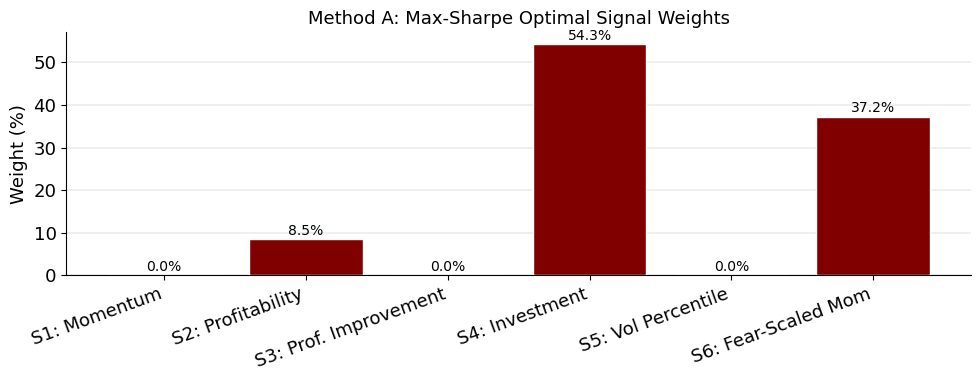

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
colors = ['maroon' if w > 0.01 else 'lightgray' for w in alpha_w]
ax.bar(SIGNAL_LABELS, alpha_w * 100, color=colors, edgecolor='white', zorder=5)
ax.set_title("Method A: Max-Sharpe Optimal Signal Weights", fontsize=13)
ax.set_ylabel("Weight (%)")
ax.set_xticklabels(SIGNAL_LABELS, rotation=20, ha='right')
for idx, (v, w) in enumerate(zip(alpha_w, SIGNAL_LABELS)):
    ax.text(idx, v * 100 + 0.3, f'{v*100:.1f}%', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig('fig_methodA_weights.png', dpi=120)
plt.show(); plt.close()

In [22]:
# ============================================================
# 3.3  METHOD B — Ridge/ElasticNet Walk-Forward
# ============================================================

print("\n> Method B: Ridge Walk-Forward ML (train_window = %d months) …" % TRAIN_WINDOW)

dates = sorted(df_samp['ldate'].unique())
predictions_B = []
coef_history  = []

for t_idx in range(TRAIN_WINDOW, len(dates)):
    train_dates = dates[t_idx - TRAIN_WINDOW: t_idx]
    test_date   = dates[t_idx]

    train_df = df_samp[df_samp['ldate'].isin(train_dates)].copy()
    test_df  = df_samp[df_samp['ldate'] == test_date].copy()

    X_train_raw = train_df[SIGNAL_NAMES]
    y_train_raw = train_df['ret_next']

    valid_mask = X_train_raw.notna().all(axis=1) & y_train_raw.notna()
    X_train    = X_train_raw[valid_mask].values
    y_train    = y_train_raw[valid_mask].values

    if len(X_train) < 50:
        continue

    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_train)

    # RidgeCV selects regularisation via cross-validation
    model = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100, 500], cv=5)
    model.fit(X_tr_sc, y_train)

    # Record coefficients
    coef_history.append({
        'ldate': test_date,
        **dict(zip(SIGNAL_LABELS, model.coef_))
    })

    # Predict for test month
    X_test_raw = test_df[SIGNAL_NAMES].fillna(0).values
    X_te_sc    = scaler.transform(X_test_raw)
    preds      = model.predict(X_te_sc)

    pred_series = pd.Series(preds, index=test_df.index, name='signal_B')
    predictions_B.append(pd.concat([test_df[['permno', 'ldate']], pred_series], axis=1))

df_pred_B = pd.concat(predictions_B, ignore_index=True)
# Merge back
df_samp = df_samp.merge(df_pred_B[['permno', 'ldate', 'signal_B']],
                         on=['permno', 'ldate'], how='left')
# Cross-sectional normalise
df_samp['signal_B'] = df_samp.groupby('ldate')['signal_B'].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
).clip(-3, 3)

ls_B = compute_ls_returns(df_samp.dropna(subset=['signal_B']), 'signal_B', NUM_PORT)
ann_ret_B = ls_B.mean() * 12
ann_vol_B = ls_B.std() * np.sqrt(12)
sharpe_B  = ann_ret_B / ann_vol_B
print(f"   Method B combined L/S: AnnRet={ann_ret_B*100:+.2f}%  AnnVol={ann_vol_B*100:.2f}%  Sharpe={sharpe_B:.3f}")


> Method B: Ridge Walk-Forward ML (train_window = 60 months) …


   Method B combined L/S: AnnRet=+12.25%  AnnVol=17.50%  Sharpe=0.700


### Ridge coefficient evolution

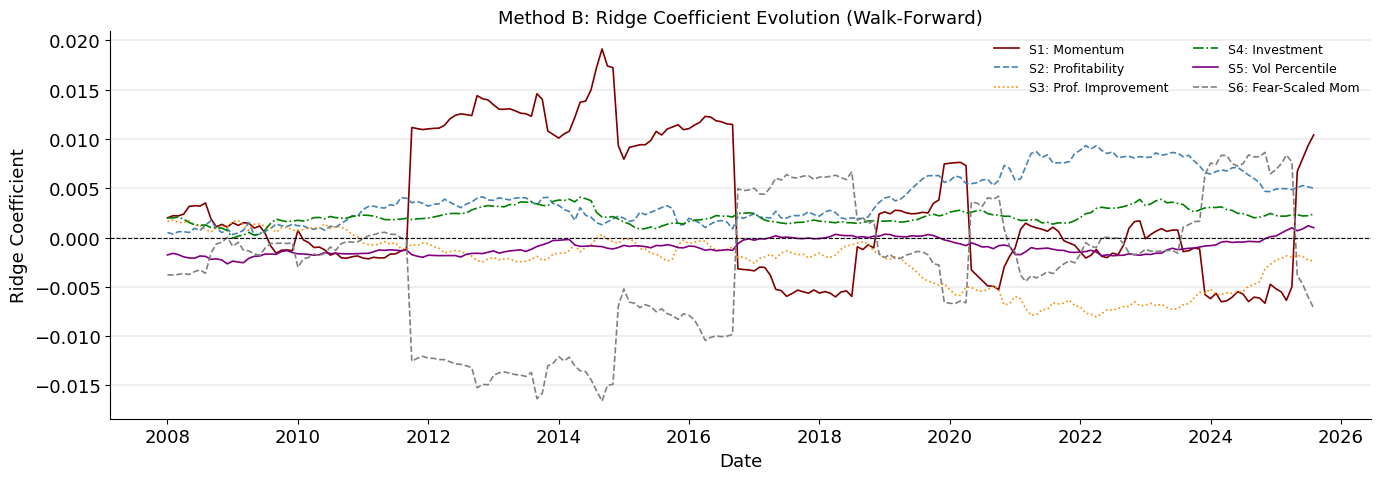

In [23]:
coef_df = pd.DataFrame(coef_history).set_index('ldate')
coef_df.index = pd.to_datetime(coef_df.index)
fig, ax = plt.subplots(figsize=(14, 5))
for col in coef_df.columns:
    ax.plot(coef_df.index, coef_df[col], lw=1.2, label=col)
ax.axhline(0, color='black', lw=0.8, linestyle='--')
ax.set_title("Method B: Ridge Coefficient Evolution (Walk-Forward)", fontsize=13)
ax.set_xlabel("Date"); ax.set_ylabel("Ridge Coefficient")
ax.legend(loc='upper right', fontsize=9, ncol=2)
plt.tight_layout()
plt.savefig('fig_methodB_coefs.png', dpi=120)
plt.show(); plt.close()

In [24]:
# ============================================================
# 3.4  COMPARE METHODS & SELECT COMBINED SIGNAL
# ============================================================

In [25]:
# ============================================================
# 3.4  TRAIN / TEST SPLIT EVALUATION
# ============================================================

print("\n> Train / Test Split Evaluation")
print(f"  Train: {SAMPLE_START} – {TRAIN_END}  |  Test (OOS): {TEST_START} – {SAMPLE_END}")
print(f"  NOTE: Method A weights trained on IS only → applied fixed to OOS")
print(f"        Method B always OOS by walk-forward construction")
print()

# Method A: IS vs OOS
perf_summary(ls_A_IS,  "Method A  IS   (weights estimated here)")
perf_summary(ls_A_OOS, "Method A  OOS  (weights FIXED from IS → applied OOS)")

# Method B: IS vs OOS (walk-forward, both are technically OOS per fold)
ls_B_IS  = ls_B[ls_B.index <= TRAIN_END]   if not ls_B.empty else pd.Series(dtype=float)
ls_B_OOS = ls_B[ls_B.index >= TEST_START]  if not ls_B.empty else pd.Series(dtype=float)
if not ls_B_IS.empty:
    perf_summary(ls_B_IS,  "Method B  IS   (walk-forward, always OOS per fold)")
if not ls_B_OOS.empty:
    perf_summary(ls_B_OOS, "Method B  OOS  (walk-forward, always OOS per fold)")

# IS vs OOS degradation check
def sharpe(s):
    return (s.mean() * 12) / (s.std() * np.sqrt(12)) if s.std() > 0 else 0

print(f"\n  Sharpe degradation check (IS → OOS):")
print(f"    Method A:  IS={sharpe(ls_A_IS):.3f}  →  OOS={sharpe(ls_A_OOS):.3f}  "
      f"(ratio={sharpe(ls_A_OOS)/sharpe(ls_A_IS):.2f})")
if not ls_B_IS.empty and not ls_B_OOS.empty:
    print(f"    Method B:  IS={sharpe(ls_B_IS):.3f}  →  OOS={sharpe(ls_B_OOS):.3f}  "
          f"(ratio={sharpe(ls_B_OOS)/sharpe(ls_B_IS):.2f})")


> Train / Test Split Evaluation
  Train: 2003-01-01 – 2013-12-31  |  Test (OOS): 2014-01-01 – 2025-08-01
  NOTE: Method A weights trained on IS only → applied fixed to OOS
        Method B always OOS by walk-forward construction

   Method A  IS   (weights estimated here)   AnnRet=+7.54%  AnnVol=15.34%  Sharpe=0.491  MaxDD=-44.26%
   Method A  OOS  (weights FIXED from IS → applied OOS)  AnnRet=+5.37%  AnnVol=18.62%  Sharpe=0.289  MaxDD=-43.25%
   Method B  IS   (walk-forward, always OOS per fold)  AnnRet=+19.51%  AnnVol=15.23%  Sharpe=1.281  MaxDD=-11.70%
   Method B  OOS  (walk-forward, always OOS per fold)  AnnRet=+8.53%  AnnVol=18.52%  Sharpe=0.460  MaxDD=-38.47%

  Sharpe degradation check (IS → OOS):
    Method A:  IS=0.491  →  OOS=0.289  (ratio=0.59)
    Method B:  IS=1.281  →  OOS=0.460  (ratio=0.36)


### Cumulative returns: IS vs OOS split, both methods

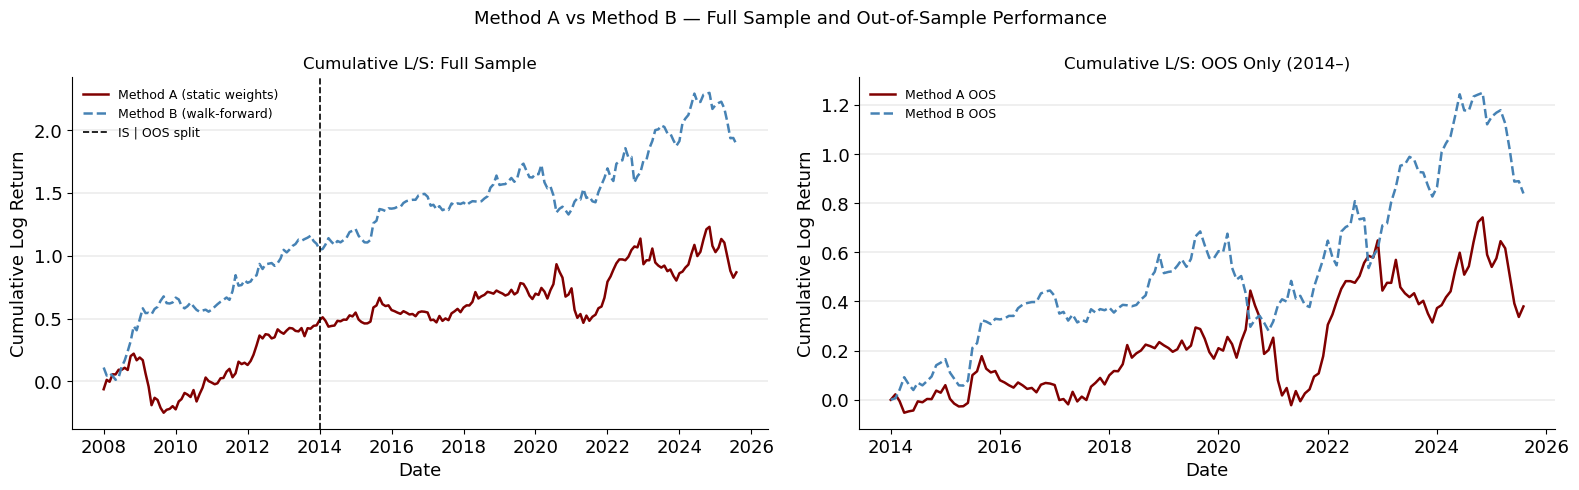

In [26]:
common_dates = ls_A.index.intersection(ls_B.index)
ls_A_c = ls_A.loc[common_dates]
ls_B_c = ls_B.loc[common_dates]

cum_A = np.log(1 + ls_A_c.fillna(0)).cumsum()
cum_B = np.log(1 + ls_B_c.fillna(0)).cumsum()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: full-period comparison
axes[0].plot(cum_A.index, cum_A.values, color='maroon',    lw=1.8, label='Method A (static weights)')
axes[0].plot(cum_B.index, cum_B.values, color='steelblue', lw=1.8, label='Method B (walk-forward)')
axes[0].axvline(pd.Timestamp(TEST_START), color='black', lw=1.2, linestyle='--', label='IS | OOS split')
axes[0].set_title("Cumulative L/S: Full Sample", fontsize=12)
axes[0].set_xlabel("Date"); axes[0].set_ylabel("Cumulative Log Return")
axes[0].legend(fontsize=9)

# Right: OOS period only
oos_A = np.log(1 + ls_A_OOS.fillna(0)).cumsum()
oos_B_s = ls_B[ls_B.index >= TEST_START]
oos_B = np.log(1 + oos_B_s.fillna(0)).cumsum()
axes[1].plot(oos_A.index, oos_A.values - oos_A.iloc[0] if len(oos_A) else [],
             color='maroon',    lw=1.8, label='Method A OOS')
axes[1].plot(oos_B.index, oos_B.values - oos_B.iloc[0] if len(oos_B) else [],
             color='steelblue', lw=1.8, label='Method B OOS')
axes[1].set_title(f"Cumulative L/S: OOS Only ({TEST_START[:4]}–)", fontsize=12)
axes[1].set_xlabel("Date"); axes[1].set_ylabel("Cumulative Log Return")
axes[1].legend(fontsize=9)

plt.suptitle("Method A vs Method B — Full Sample and Out-of-Sample Performance", fontsize=13)
plt.tight_layout()
plt.savefig('fig_compare_AB.png', dpi=120)
plt.show(); plt.close()

### IS vs OOS Sharpe bar chart

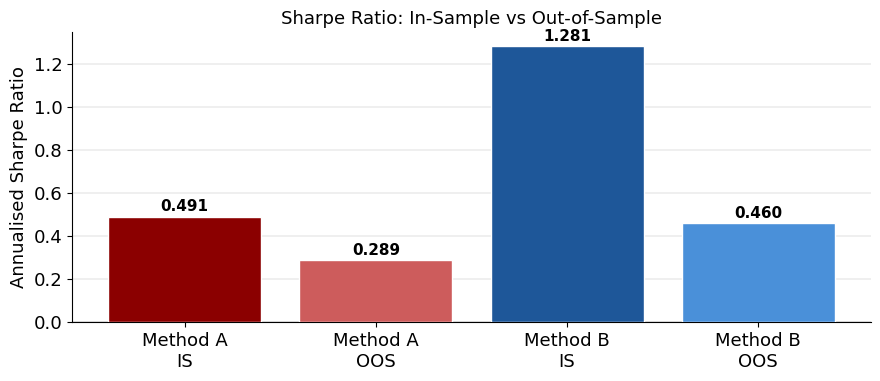

In [27]:
_labels = ['Method A\nIS', 'Method A\nOOS', 'Method B\nIS', 'Method B\nOOS']
_sharpes = [sharpe(ls_A_IS), sharpe(ls_A_OOS),
            sharpe(ls_B_IS) if not ls_B_IS.empty else 0,
            sharpe(ls_B_OOS) if not ls_B_OOS.empty else 0]
_colors = ['#8B0000', '#CD5C5C', '#1E5799', '#4A90D9']

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(_labels, _sharpes, color=_colors, edgecolor='white', zorder=5)
ax.axhline(0, color='black', lw=0.8)
ax.set_title("Sharpe Ratio: In-Sample vs Out-of-Sample", fontsize=13)
ax.set_ylabel("Annualised Sharpe Ratio")
for bar, v in zip(bars, _sharpes):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.3f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_IS_OOS_sharpe.png', dpi=120)
plt.show(); plt.close()

### Final combined signal (blend A + B, applied to FULL sample)

In [28]:
sharpe_A_c = sharpe(ls_A_c)
sharpe_B_c = sharpe(ls_B_c)
print(f"\n  Full-sample Sharpe — A: {sharpe_A_c:.3f}  |  B: {sharpe_B_c:.3f}")

if 'signal_B' in df_samp.columns:
    df_samp['signal_combined'] = (
        0.5 * df_samp['signal_A'].fillna(0) +
        0.5 * df_samp['signal_B'].fillna(0)
    )
else:
    df_samp['signal_combined'] = df_samp['signal_A']

df_samp['signal_combined'] = df_samp.groupby('ldate')['signal_combined'].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
).clip(-3, 3)

print("\n  Combined signal = 50/50 blend of Method A (OOS weights) + Method B (walk-forward).")


  Full-sample Sharpe — A: 0.365  |  B: 0.700

  Combined signal = 50/50 blend of Method A (OOS weights) + Method B (walk-forward).


## Section 4: Portfolio Construction

In [29]:
# ============================================================
# SECTION 4 : PORTFOLIO CONSTRUCTION
# ============================================================

print("\n" + "="*60)
print("SECTION 4 : PORTFOLIO CONSTRUCTION")
print("="*60)
print("> Long top 10%, Short bottom 10% on signal_combined …")

df_port = df_samp.dropna(subset=['signal_combined', 'me_lagged', 'daret']).copy()

# Sort into deciles each month
portfolio_rets = []
holdings_log   = []

for dt, grp in df_port.groupby('ldate'):
    grp = grp.copy()
    if len(grp) < 50:
        continue
    try:
        grp['portfolio'] = pd.qcut(grp['signal_combined'], NUM_PORT, labels=False,
                                    duplicates='drop') + 1
    except ValueError:
        continue
    if grp['portfolio'].nunique() < 2:
        continue

    # Value-weighted return within each decile
    def vw_ret(sub):
        if sub.empty or sub['me_lagged'].sum() == 0:
            return np.nan
        w = sub['me_lagged'] / sub['me_lagged'].sum()
        return (w * sub['daret']).sum()

    p_max = int(grp['portfolio'].max())
    p_min = int(grp['portfolio'].min())
    port_row = {'ldate': dt}
    for p in range(1, NUM_PORT + 1):
        sub = grp[grp['portfolio'] == p]
        port_row[f'P{p}'] = vw_ret(sub) if len(sub) > 0 else np.nan
    port_row['LS']        = (port_row.get(f'P{p_max}', np.nan) or 0) - (port_row.get(f'P{p_min}', np.nan) or 0)
    port_row['n_long']    = (grp['portfolio'] == p_max).sum()
    port_row['n_short']   = (grp['portfolio'] == p_min).sum()
    port_row['n_total']   = len(grp)
    portfolio_rets.append(port_row)

    # Track top/bottom holdings
    long_names  = grp[grp['portfolio'] == p_max][['ticker', 'me_lagged']].nlargest(5, 'me_lagged')
    short_names = grp[grp['portfolio'] == p_min][['ticker', 'me_lagged']].nlargest(5, 'me_lagged')
    holdings_log.append({'ldate': dt, 'long_top5': list(long_names['ticker']),
                         'short_top5': list(short_names['ticker'])})

df_port_rets = pd.DataFrame(portfolio_rets).set_index('ldate')
df_port_rets.index = pd.to_datetime(df_port_rets.index)
print(f"  Portfolio return series: {df_port_rets.shape[0]} months")


SECTION 4 : PORTFOLIO CONSTRUCTION
> Long top 10%, Short bottom 10% on signal_combined …


  Portfolio return series: 272 months


### Average return per decile bar chart

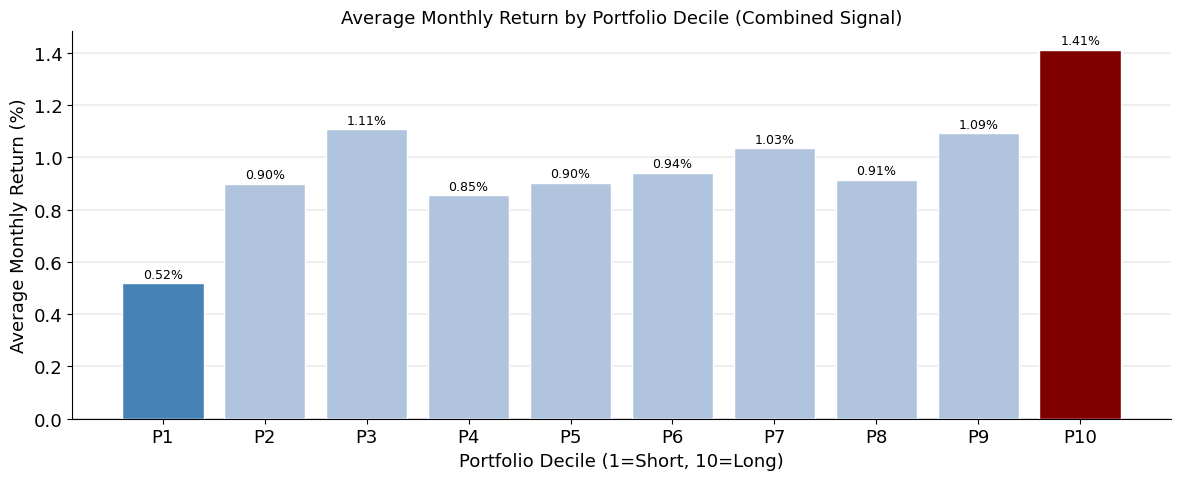

In [30]:
port_cols = [f'P{i}' for i in range(1, NUM_PORT + 1)]
avg_port  = df_port_rets[port_cols].mean() * 100

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['steelblue'] + ['lightsteelblue'] * (NUM_PORT - 2) + ['maroon']
ax.bar(port_cols, avg_port.values, color=colors, edgecolor='white', zorder=5)
ax.axhline(0, color='black', lw=0.8)
ax.set_title("Average Monthly Return by Portfolio Decile (Combined Signal)", fontsize=13)
ax.set_xlabel("Portfolio Decile (1=Short, 10=Long)")
ax.set_ylabel("Average Monthly Return (%)")
for idx, v in enumerate(avg_port.values):
    ax.text(idx, v + 0.01, f'{v:.2f}%', ha='center', va='bottom', fontsize=9,
            color='black')
plt.tight_layout()
plt.savefig('fig_avg_port_ret.png', dpi=120)
plt.show(); plt.close()

### Portfolio size over time

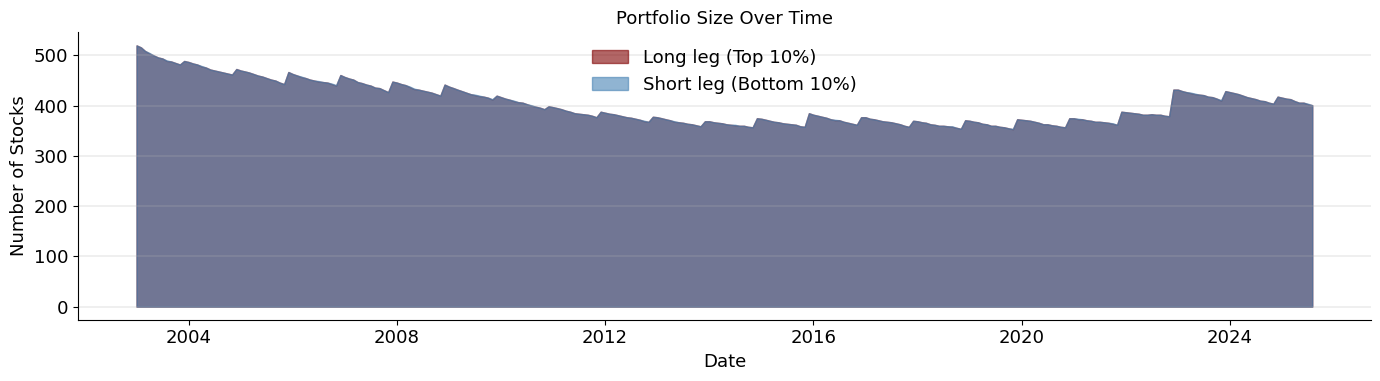


  Sample holdings (last 3 months):
  2025-06-01  LONG: ['TSLA', 'WMT', 'ORCL', 'HD', 'PLTR']  SHORT: ['AVGO', 'UBS', 'COIN', 'XYL', 'SMCI']
  2025-07-01  LONG: ['TSLA', 'WMT', 'PLTR', 'BKNG', 'LOW']  SHORT: ['SMCI', 'QXO', 'BBIO', 'ROIV', 'IONS']
  2025-08-01  LONG: ['META', 'TSLA', 'WMT', 'PLTR', 'BKNG']  SHORT: ['SMCI', 'ASTS', 'QXO', 'BBIO', 'LCID']


In [31]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(df_port_rets.index, df_port_rets['n_long'], alpha=0.6,
                color='maroon', label='Long leg (Top 10%)')
ax.fill_between(df_port_rets.index, df_port_rets['n_short'], alpha=0.6,
                color='steelblue', label='Short leg (Bottom 10%)')
ax.set_title("Portfolio Size Over Time", fontsize=13)
ax.set_xlabel("Date"); ax.set_ylabel("Number of Stocks")
ax.legend()
plt.tight_layout()
plt.savefig('fig_port_size.png', dpi=120)
plt.show(); plt.close()

# Last 3 months holdings snapshot
print("\n  Sample holdings (last 3 months):")
for rec in holdings_log[-3:]:
    print(f"  {rec['ldate'].date()}  LONG: {rec['long_top5']}  SHORT: {rec['short_top5']}")

## Section 4.5: EPU-Based Position Scaling (仓位管理)

In [32]:
# ============================================================
# SECTION 4.5 : EPU-BASED POSITION SCALING (TIMING / 仓位管理)
# ============================================================
# Logic:
#   High EPU (top 10 percentile)  → uncertainty is elevated → scale positions to 0.5×
#   Low  EPU (bot 10 percentile)  → calm / low-uncertainty  → scale positions to 2.0×
#   Otherwise                     → normal                   → scale = 1.0×
#
# Both the long leg and short leg are scaled by the same factor,
# which is equivalent to multiplying the L/S return by that factor.
# ============================================================

print("\n" + "="*60)
print("SECTION 4.5 : EPU-BASED POSITION SCALING")
print("="*60)


SECTION 4.5 : EPU-BASED POSITION SCALING


### 4.5.1  Load & parse EPU data

In [33]:
EPU_FILE = 'US_Policy_Uncertainty_Data.xlsx'
print(f"> Loading {EPU_FILE} …")
epu_raw = pd.read_excel(os.path.join(DATA_DIR, EPU_FILE))
epu_raw.columns = ['Year', 'Month', 'EPU']
epu_raw = epu_raw.dropna(subset=['Year', 'Month', 'EPU'])
epu_raw['Year'] = epu_raw['Year'].astype(str).str.strip()
epu_raw = epu_raw[epu_raw['Year'].str.match(r'^\d{4}$')]     # drop footnote rows
epu_raw['Year']  = epu_raw['Year'].astype(int)
epu_raw['Month'] = epu_raw['Month'].astype(int)
# Build first-of-month timestamp (matches portfolio ldate convention: 2003-01-01)
epu_raw['ldate'] = pd.to_datetime(
    epu_raw['Year'].astype(str) + '-' +
    epu_raw['Month'].astype(str).str.zfill(2) + '-01'
)

# Keep only sample period
epu = epu_raw[
    (epu_raw['ldate'] >= pd.Timestamp(SAMPLE_START)) &
    (epu_raw['ldate'] <= pd.Timestamp(SAMPLE_END))
][['ldate', 'EPU']].sort_values('ldate').reset_index(drop=True)

print(f"  EPU data: {len(epu)} months  "
      f"({epu['ldate'].min().date()} → {epu['ldate'].max().date()})")
print(f"  EPU range: {epu['EPU'].min():.1f} – {epu['EPU'].max():.1f}"
      f"  (mean={epu['EPU'].mean():.1f},  median={epu['EPU'].median():.1f})")

> Loading US_Policy_Uncertainty_Data.xlsx …
  EPU data: 272 months  (2003-01-01 → 2025-08-01)
  EPU range: 44.8 – 724.9  (mean=150.0,  median=130.2)


### 4.5.2  Compute regime labels (full-sample percentile thresholds)

In [34]:
HIGH_EPU_PCT  = 0.90    # top 10% → reduce exposure (uncertainty spike)
LOW_EPU_PCT   = 0.10    # bot 10% → double exposure  (calm market)
HIGH_LEVERAGE = 0.5
LOW_LEVERAGE  = 2.0
MID_LEVERAGE  = 1.0

high_thresh = epu['EPU'].quantile(HIGH_EPU_PCT)
low_thresh  = epu['EPU'].quantile(LOW_EPU_PCT)

epu['leverage'] = MID_LEVERAGE
epu.loc[epu['EPU'] >= high_thresh, 'leverage'] = HIGH_LEVERAGE   # uncertainty spike → reduce
epu.loc[epu['EPU'] <= low_thresh,  'leverage'] = LOW_LEVERAGE    # calm period        → amplify

epu['regime'] = 'Normal (×1.0)'
epu.loc[epu['EPU'] >= high_thresh, 'regime'] = 'High EPU (×0.5)'
epu.loc[epu['EPU'] <= low_thresh,  'regime'] = 'Low EPU  (×2.0)'

n_hi  = (epu['regime'] == 'High EPU (×0.5)').sum()
n_lo  = (epu['regime'] == 'Low EPU  (×2.0)').sum()
n_mid = (epu['regime'] == 'Normal (×1.0)').sum()

print(f"\n  Regime thresholds (full-sample):")
print(f"    90th pctile (High EPU → ×0.5): {high_thresh:.1f}")
print(f"    10th pctile (Low  EPU → ×2.0): {low_thresh:.1f}")
print(f"  Regime month counts — High(×0.5): {n_hi}  Normal(×1.0): {n_mid}  Low(×2.0): {n_lo}")


  Regime thresholds (full-sample):
    90th pctile (High EPU → ×0.5): 226.5
    10th pctile (Low  EPU → ×2.0): 78.4
  Regime month counts — High(×0.5): 28  Normal(×1.0): 216  Low(×2.0): 28


### 4.5.3  Apply leverage to portfolio L/S returns

In [35]:
df_port_rets_epu = df_port_rets.copy()
df_port_rets_epu = df_port_rets_epu.join(
    epu.set_index('ldate')[['EPU', 'leverage', 'regime']]
)
df_port_rets_epu['leverage'] = df_port_rets_epu['leverage'].fillna(MID_LEVERAGE)

# Scaled LS return  =  unscaled LS  ×  leverage_scalar
df_port_rets_epu['LS_orig'] = df_port_rets_epu['LS'].copy()   # keep raw for comparison
df_port_rets_epu['LS_epu']  = df_port_rets_epu['LS'] * df_port_rets_epu['leverage']

# Quick stats comparison
def _perf(s, label):
    ann_r = s.mean() * 12
    ann_v = s.std()  * np.sqrt(12)
    sr    = ann_r / ann_v if ann_v > 0 else 0
    mdd   = (np.log(1 + s.fillna(0)).cumsum() -
             np.log(1 + s.fillna(0)).cumsum().cummax()).min()
    print(f"  {label:45s}  AnnRet={ann_r*100:+.2f}%  AnnVol={ann_v*100:.2f}%  "
          f"Sharpe={sr:.3f}  MaxDD={mdd*100:.2f}%")

print()
_perf(df_port_rets_epu['LS_orig'], "Unscaled L/S (baseline, ×1.0 always)")
_perf(df_port_rets_epu['LS_epu'],  "EPU-Scaled L/S (×0.5/×1.0/×2.0 timing)")


  Unscaled L/S (baseline, ×1.0 always)           AnnRet=+10.71%  AnnVol=15.99%  Sharpe=0.670  MaxDD=-50.86%
  EPU-Scaled L/S (×0.5/×1.0/×2.0 timing)         AnnRet=+11.70%  AnnVol=15.77%  Sharpe=0.741  MaxDD=-30.90%


### 4.5.4  Visualisation A: EPU index + regime shading

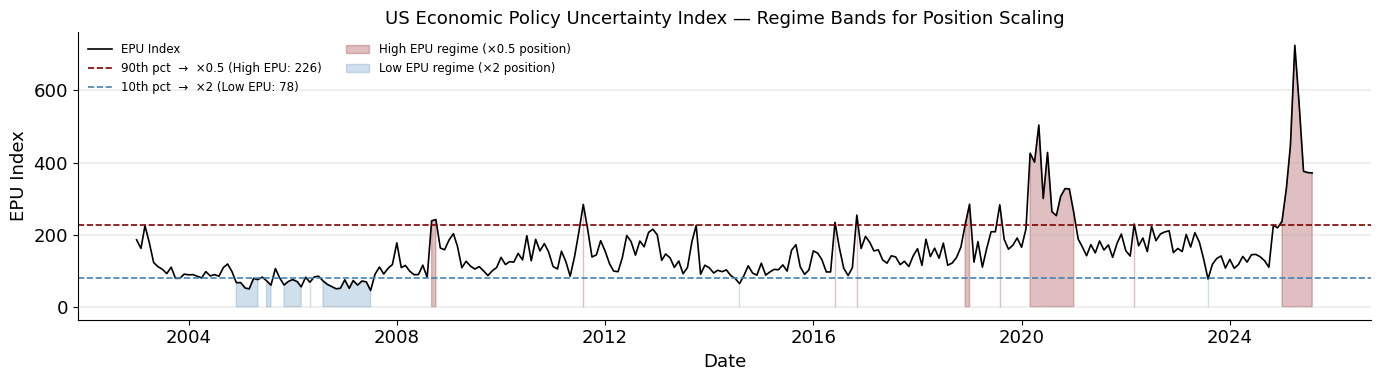

In [36]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(epu['ldate'], epu['EPU'], color='black', lw=1.2, label='EPU Index')
ax.axhline(high_thresh, color='maroon',    lw=1.2, linestyle='--',
           label=f'90th pct  →  ×{HIGH_LEVERAGE} (High EPU: {high_thresh:.0f})')
ax.axhline(low_thresh,  color='steelblue', lw=1.2, linestyle='--',
           label=f'10th pct  →  ×{int(LOW_LEVERAGE)} (Low EPU: {low_thresh:.0f})')
ax.fill_between(epu['ldate'], epu['EPU'],
                where=(epu['EPU'] >= high_thresh),
                color='maroon', alpha=0.25, label=f'High EPU regime (×{HIGH_LEVERAGE} position)')
ax.fill_between(epu['ldate'], epu['EPU'],
                where=(epu['EPU'] <= low_thresh),
                color='steelblue', alpha=0.25, label=f'Low EPU regime (×{int(LOW_LEVERAGE)} position)')
ax.set_title("US Economic Policy Uncertainty Index — Regime Bands for Position Scaling",
             fontsize=13)
ax.set_xlabel("Date"); ax.set_ylabel("EPU Index")
ax.legend(fontsize=8.5, ncol=2)
plt.tight_layout()
plt.savefig('fig_epu_regime.png', dpi=120)
plt.show(); plt.close()

### 4.5.5  Visualisation B: Cumulative L/S — Unscaled vs EPU-Scaled

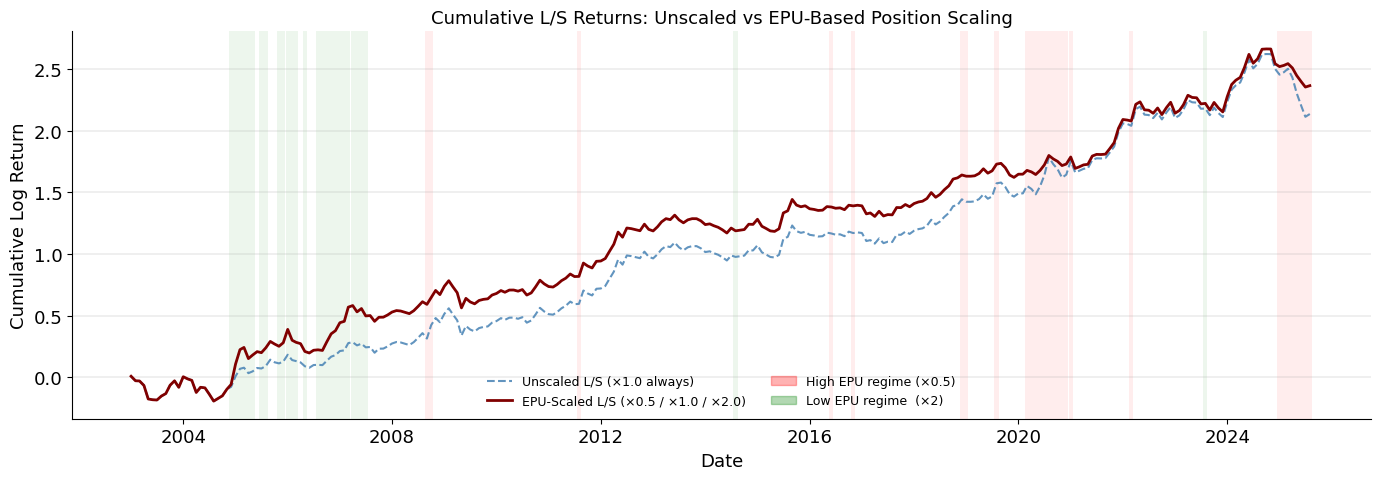

In [37]:
_common = df_port_rets_epu.dropna(subset=['LS_orig', 'LS_epu'])
cum_orig = np.log(1 + _common['LS_orig'].fillna(0)).cumsum()
cum_epu  = np.log(1 + _common['LS_epu'].fillna(0)).cumsum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(_common.index, cum_orig.values, color='steelblue', lw=1.5,
        linestyle='--', label='Unscaled L/S (×1.0 always)', alpha=0.85)
ax.plot(_common.index, cum_epu.values,  color='maroon',    lw=2.0,
        label='EPU-Scaled L/S (×0.5 / ×1.0 / ×2.0)')

# Shade regime months on the chart
for _, row in epu.iterrows():
    if row['regime'] == 'Normal (×1.0)':
        continue
    clr = 'red' if 'High' in row['regime'] else 'green'
    ax.axvspan(row['ldate'] - pd.DateOffset(days=15),
               row['ldate'] + pd.DateOffset(days=15),
               alpha=0.07, color=clr, linewidth=0)

ax.set_title("Cumulative L/S Returns: Unscaled vs EPU-Based Position Scaling", fontsize=13)
ax.set_xlabel("Date"); ax.set_ylabel("Cumulative Log Return")
ax.legend(fontsize=10)
# Add regime legend patches
p1 = mpatches.Patch(color='red',   alpha=0.3, label=f'High EPU regime (×{HIGH_LEVERAGE})')
p2 = mpatches.Patch(color='green', alpha=0.3, label=f'Low EPU regime  (×{int(LOW_LEVERAGE)})')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles + [p1, p2], fontsize=9, ncol=2)
plt.tight_layout()
plt.savefig('fig_epu_cum.png', dpi=120)
plt.show(); plt.close()

### 4.5.6  Visualisation C: Leverage scalar timeline

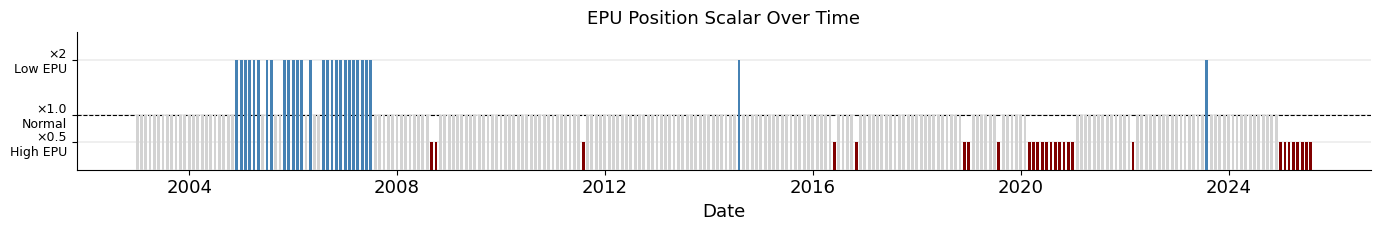

In [38]:
_lev = df_port_rets_epu[['leverage']].copy()
_lev_colors = _lev['leverage'].map({HIGH_LEVERAGE: 'maroon', MID_LEVERAGE: 'lightgray',
                                     LOW_LEVERAGE: 'steelblue'}).fillna('lightgray')
fig, ax = plt.subplots(figsize=(14, 2.5))
ax.bar(_lev.index, _lev['leverage'], color=_lev_colors, width=20, zorder=5)
ax.axhline(1.0, color='black', lw=0.8, linestyle='--')
ax.set_ylim(0, 2.5)
ax.set_yticks([HIGH_LEVERAGE, MID_LEVERAGE, LOW_LEVERAGE])
ax.set_yticklabels([f'×{HIGH_LEVERAGE}\nHigh EPU', '×1.0\nNormal', f'×{int(LOW_LEVERAGE)}\nLow EPU'],
                   fontsize=9)
ax.set_title("EPU Position Scalar Over Time", fontsize=13)
ax.set_xlabel("Date")
plt.tight_layout()
plt.savefig('fig_epu_leverage.png', dpi=120)
plt.show(); plt.close()

### Update df_port_rets so Section 5 runs on EPU-scaled returns

In [39]:
# The raw original LS is preserved in 'LS_orig'; 'LS' now holds the EPU-scaled series.
df_port_rets = df_port_rets_epu.copy()
df_port_rets['LS'] = df_port_rets_epu['LS_epu']

print("\n  → Downstream analytics (Section 5) will use EPU-scaled L/S as primary strategy.")
print(f"    (Original unscaled L/S preserved in 'LS_orig' column for reference)")


  → Downstream analytics (Section 5) will use EPU-scaled L/S as primary strategy.
    (Original unscaled L/S preserved in 'LS_orig' column for reference)


## Section 5: Portfolio Analytics

In [40]:
# ============================================================
# SECTION 5 : PORTFOLIO ANALYTICS
# ============================================================

print("\n" + "="*60)
print("SECTION 5 : PORTFOLIO ANALYTICS")
print("="*60)


SECTION 5 : PORTFOLIO ANALYTICS


### Load FF factors

In [41]:
df_ff = pd.read_parquet('FFData.parquet').rename(columns={'ldate': 'ym'})
df_ff['ym'] = pd.to_datetime(df_ff['ym'])
df_ff = df_ff.drop_duplicates('ym').sort_values('ym')

# Prepare strategy returns frame
df_strat = df_port_rets.reset_index().rename(columns={'ldate': 'ym'})
df_strat['ym'] = pd.to_datetime(df_strat['ym'])

# Merge FF
df_anal = pd.merge(df_strat, df_ff, on='ym', how='inner', validate='1:1')
df_anal = df_anal.sort_values('ym').reset_index(drop=True)

### 5.1 Summary Statistics

In [42]:
print("\n> 5.1 Summary Statistics")
ls_ret = df_anal['LS']          # EPU-scaled (primary)
ls_orig = df_anal['LS_orig']    # unscaled baseline
mkt_rf = df_anal['mktrf']
rf     = df_anal['rf']

summary_stats = {
    'L/S EPU-Scaled': ls_ret,
    'L/S Unscaled':   ls_orig,
    'Market (MktRf)': mkt_rf,
    'SMB': df_anal['smb'],
    'HML': df_anal['hml'],
    'UMD': df_anal['umd'],
}
sum_df = pd.DataFrame({
    k: {
        'Ann. Mean (%)':   v.mean() * 12 * 100,
        'Ann. Vol (%)':    v.std()  * np.sqrt(12) * 100,
        'Ann. Sharpe':     (v.mean() * 12) / (v.std() * np.sqrt(12)),
        'Skewness':        v.skew(),
        'Kurtosis':        v.kurtosis(),
        'Min Monthly (%)': v.min() * 100,
        'Max Monthly (%)': v.max() * 100,
    }
    for k, v in summary_stats.items()
}).T
print(sum_df.round(3))


> 5.1 Summary Statistics
                Ann. Mean (%)  Ann. Vol (%)  Ann. Sharpe  Skewness  Kurtosis  \
L/S EPU-Scaled         11.696        15.773        0.741     0.390     1.047   
L/S Unscaled           10.713        15.993        0.670     0.254     0.806   
Market (MktRf)         10.565        15.026        0.703    -0.539     1.384   
SMB                     0.647         9.171        0.071     0.271     0.398   
HML                    -0.346        10.714       -0.032     0.028     2.949   
UMD                     0.344        14.975        0.023    -2.255    15.091   

                Min Monthly (%)  Max Monthly (%)  
L/S EPU-Scaled          -11.600           17.943  
L/S Unscaled            -11.883           15.661  
Market (MktRf)          -17.200           13.580  
SMB                      -8.180            8.340  
HML                     -13.830           12.860  
UMD                     -34.340           12.710  


### 5.2 Cumulative Returns


> 5.2 Cumulative Returns


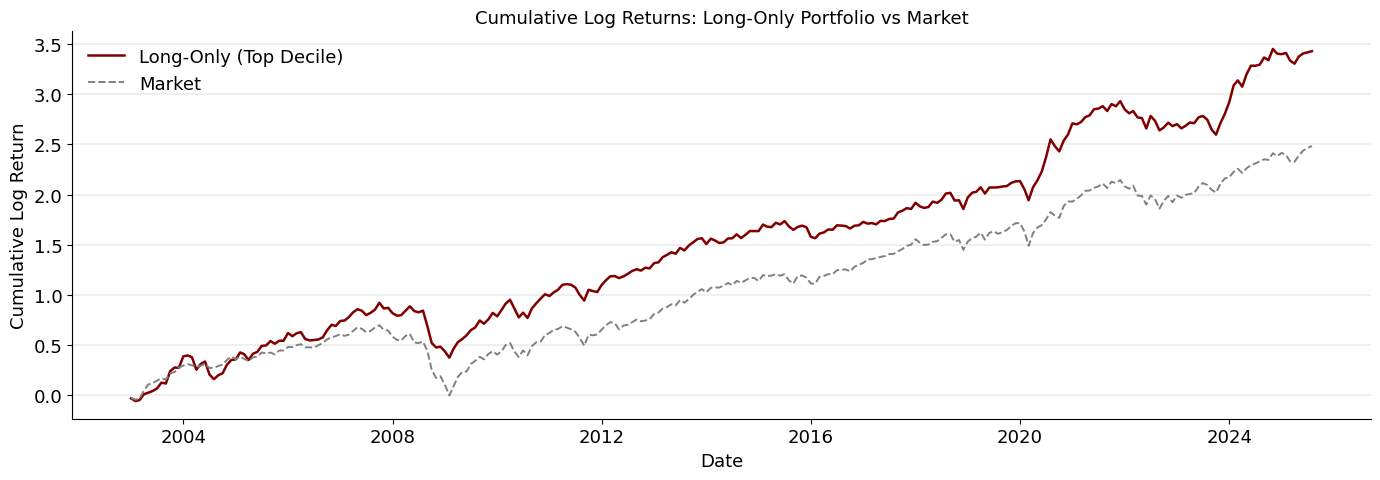

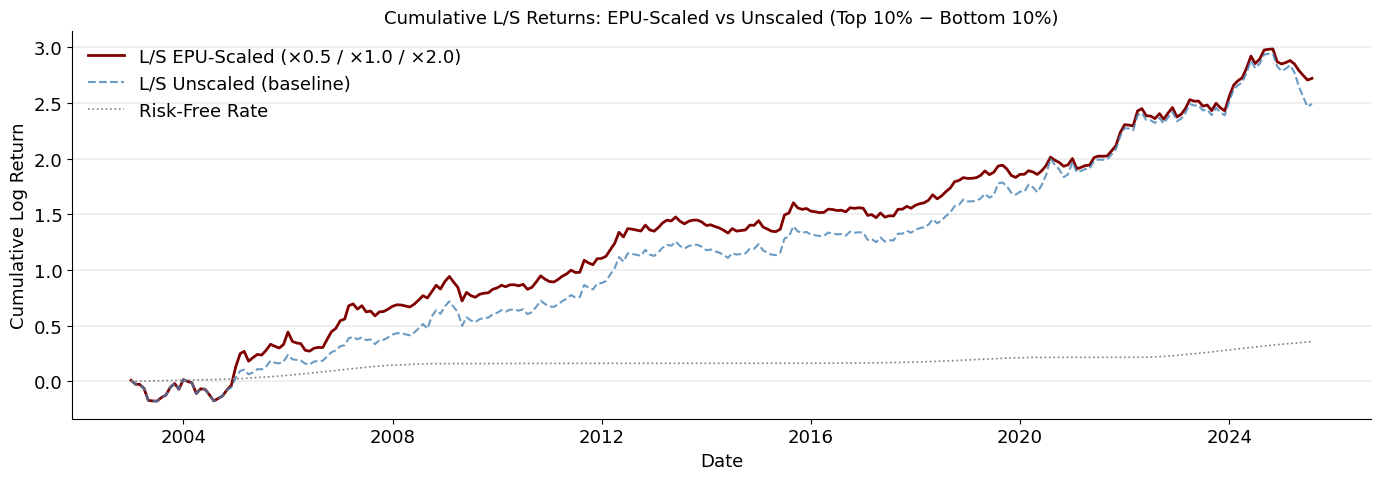

/var/folders/r8/bt55zzv131z7lwbf2b6kkxth0000gn/T/ipykernel_89806/2314379377.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('RdYlGn', NUM_PORT)


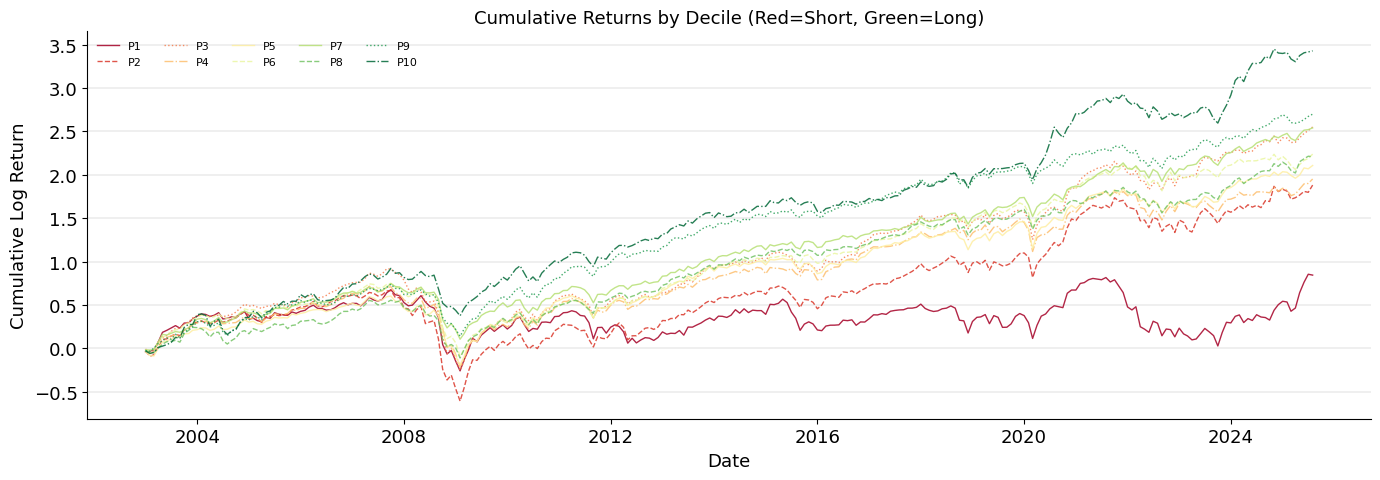

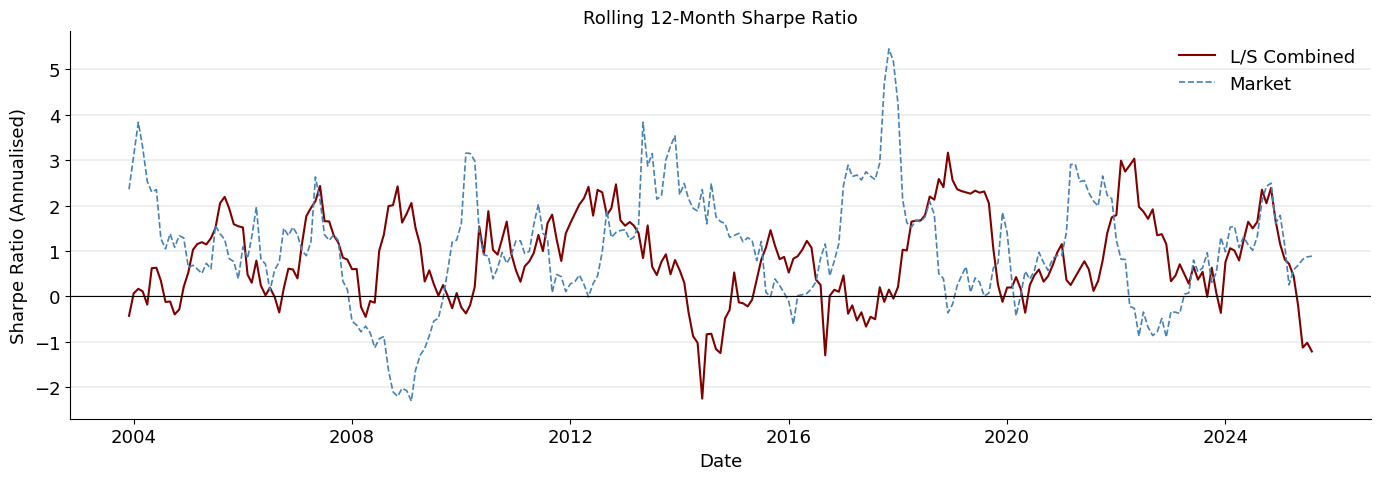

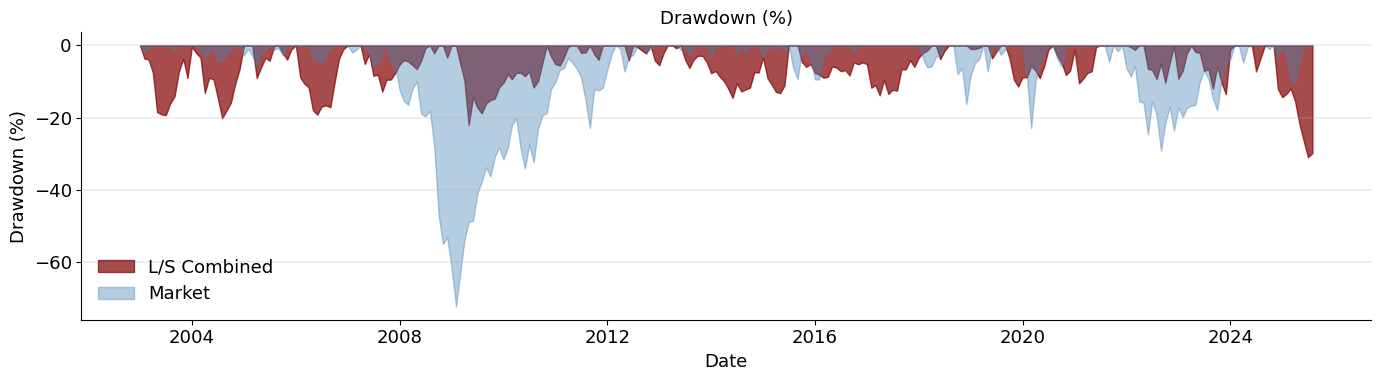

In [43]:
print("\n> 5.2 Cumulative Returns")
df_anal = df_anal.sort_values('ym')

# Long-only (top decile) cumulative vs market — use highest available decile column
_top_col = f'P{NUM_PORT}'
if _top_col not in df_anal.columns:  # fall back if NUM_PORT bins weren't all produced
    _top_col = [c for c in df_anal.columns if c.startswith('P') and c[1:].isdigit()][-1]
df_anal['CLN_long']     = np.log(1 + df_anal[_top_col].fillna(0)).cumsum()
df_anal['CLN_mkt']      = np.log(1 + df_anal['mktrf'] + df_anal['rf']).cumsum()
df_anal['CLN_rf']       = np.log(1 + df_anal['rf']).cumsum()
df_anal['CLN_ls']       = np.log(1 + df_anal['LS'].fillna(0) + df_anal['rf']).cumsum()
df_anal['CLN_ls_orig']  = np.log(1 + df_anal['LS_orig'].fillna(0) + df_anal['rf']).cumsum()

# Long-only
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_anal['ym'], df_anal['CLN_long'], color='maroon', lw=1.8, label='Long-Only (Top Decile)')
ax.plot(df_anal['ym'], df_anal['CLN_mkt'],  color='gray',   lw=1.4, linestyle='--', label='Market')
ax.set_title("Cumulative Log Returns: Long-Only Portfolio vs Market", fontsize=13)
ax.set_xlabel("Date"); ax.set_ylabel("Cumulative Log Return")
ax.legend()
plt.tight_layout()
plt.savefig('fig_cum_longonly.png', dpi=120)
plt.show(); plt.close()

# Long-Short: EPU-scaled vs unscaled vs risk-free
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_anal['ym'], df_anal['CLN_ls'],      color='maroon',    lw=2.0,
        label='L/S EPU-Scaled (×0.5 / ×1.0 / ×2.0)')
ax.plot(df_anal['ym'], df_anal['CLN_ls_orig'], color='steelblue', lw=1.5,
        linestyle='--', label='L/S Unscaled (baseline)', alpha=0.8)
ax.plot(df_anal['ym'], df_anal['CLN_rf'],      color='gray',      lw=1.2,
        linestyle=':',  label='Risk-Free Rate')
ax.set_title("Cumulative L/S Returns: EPU-Scaled vs Unscaled (Top 10% − Bottom 10%)", fontsize=13)
ax.set_xlabel("Date"); ax.set_ylabel("Cumulative Log Return")
ax.legend()
plt.tight_layout()
plt.savefig('fig_cum_longshort.png', dpi=120)
plt.show(); plt.close()

# All deciles cumulative
fig, ax = plt.subplots(figsize=(14, 5))
cmap = plt.cm.get_cmap('RdYlGn', NUM_PORT)
for i, p in enumerate(range(1, NUM_PORT + 1)):
    col = f'P{p}'
    if col in df_anal.columns:
        cum = np.log(1 + df_anal[col].fillna(0)).cumsum()
        ax.plot(df_anal['ym'], cum, color=cmap(i), lw=1.0, label=f'P{p}', alpha=0.85)
ax.set_title("Cumulative Returns by Decile (Red=Short, Green=Long)", fontsize=13)
ax.set_xlabel("Date"); ax.set_ylabel("Cumulative Log Return")
ax.legend(ncol=5, fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig('fig_cum_all_deciles.png', dpi=120)
plt.show(); plt.close()

# Rolling 12-month Sharpe
def rolling_sharpe(ret_series, window=12):
    r = ret_series.rolling(window)
    return (r.mean() / r.std()) * np.sqrt(12)

df_anal['roll_sharpe_ls']  = rolling_sharpe(df_anal['LS'].fillna(0))
df_anal['roll_sharpe_mkt'] = rolling_sharpe(df_anal['mktrf'])

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_anal['ym'], df_anal['roll_sharpe_ls'],  color='maroon',    lw=1.5, label='L/S Combined')
ax.plot(df_anal['ym'], df_anal['roll_sharpe_mkt'], color='steelblue', lw=1.2, linestyle='--', label='Market')
ax.axhline(0, color='black', lw=0.8)
ax.set_title("Rolling 12-Month Sharpe Ratio", fontsize=13)
ax.set_xlabel("Date"); ax.set_ylabel("Sharpe Ratio (Annualised)")
ax.legend()
plt.tight_layout()
plt.savefig('fig_rolling_sharpe.png', dpi=120)
plt.show(); plt.close()

# Drawdown
def max_drawdown(ret_series):
    cum = ret_series.fillna(0).cumsum()
    return cum - cum.cummax()

df_anal['dd_ls']  = max_drawdown(np.log(1 + df_anal['LS'].fillna(0)))
df_anal['dd_mkt'] = max_drawdown(np.log(1 + df_anal['mktrf']))

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(df_anal['ym'], df_anal['dd_ls'] * 100,  alpha=0.7, color='maroon',    label='L/S Combined')
ax.fill_between(df_anal['ym'], df_anal['dd_mkt'] * 100, alpha=0.4, color='steelblue', label='Market')
ax.set_title("Drawdown (%)", fontsize=13)
ax.set_xlabel("Date"); ax.set_ylabel("Drawdown (%)")
ax.legend()
plt.tight_layout()
plt.savefig('fig_drawdown.png', dpi=120)
plt.show(); plt.close()

### 5.3 Factor Regressions

In [44]:
print("\n> 5.3 Factor Regressions")

def make_reg_ready(df_in, cols):
    d = df_in[cols].copy()
    d = d.replace({pd.NA: np.nan})
    for c in cols:
        if d[c].dtype.name in ['Float64', 'Int64', 'Int32']:
            d[c] = d[c].astype('float64')
    return d.dropna()

df_anal['LS_e']      = df_anal['LS']      - df_anal['rf']   # EPU-scaled excess return
df_anal['LS_orig_e'] = df_anal['LS_orig'] - df_anal['rf']   # unscaled excess return
df_anal['P10_e']     = df_anal[_top_col].fillna(0) - df_anal['rf']


> 5.3 Factor Regressions


### CAPM + 3FF + 5FF + 6FF  (EPU-scaled L/S)

In [45]:
print("\n  === Factor Regressions: EPU-Scaled L/S (primary) ===")

reg_cols = ['LS', 'LS_e', 'LS_orig', 'LS_orig_e', 'P10_e',
            'mktrf', 'smb', 'hml', 'rmw', 'cma', 'umd']
reg_df = make_reg_ready(df_anal, reg_cols)

m1 = sm.OLS(reg_df['LS'],        sm.add_constant(reg_df['mktrf'])).fit()
m2 = sm.OLS(reg_df['LS_e'],      sm.add_constant(reg_df['mktrf'])).fit()
m3 = sm.OLS(reg_df['LS'],        sm.add_constant(reg_df[['mktrf','smb','hml']])).fit()
m4 = sm.OLS(reg_df['LS'],        sm.add_constant(reg_df[['mktrf','smb','hml','rmw','cma']])).fit()
m5 = sm.OLS(reg_df['LS'],        sm.add_constant(reg_df[['mktrf','smb','hml','rmw','cma','umd']])).fit()
m6 = sm.OLS(reg_df['P10_e'],     sm.add_constant(reg_df[['mktrf','smb','hml','rmw','cma','umd']])).fit()

# Unscaled baseline — 6FF only (for comparison)
m5_orig = sm.OLS(reg_df['LS_orig'], sm.add_constant(reg_df[['mktrf','smb','hml','rmw','cma','umd']])).fit()

tab = summary_col(
    [m1, m2, m3, m4, m5, m5_orig, m6],
    regressor_order=['const', 'mktrf', 'smb', 'hml', 'rmw', 'cma', 'umd'],
    stars=True, drop_omitted=True,
    model_names=['CAPM-LS', 'CAPM-LSe', '3FF-LS', '5FF-LS',
                 '6FF-EPU', '6FF-Raw', '6FF-LO'],
    info_dict={
        'N':  lambda x: f"{int(x.nobs)}",
        'R²': lambda x: f"{x.rsquared:.3f}",
    }
)
print(tab)
print("Models: CAPM/3FF/5FF use EPU-scaled LS; 6FF-EPU=EPU-scaled; 6FF-Raw=unscaled baseline; LO=Long-Only P10")


  === Factor Regressions: EPU-Scaled L/S (primary) ===

                CAPM-LS    CAPM-LSe    3FF-LS    5FF-LS    6FF-EPU   6FF-Raw    6FF-LO  
----------------------------------------------------------------------------------------
const          0.0115***  0.0102***  0.0112*** 0.0091***  0.0081*** 0.0075*** 0.0025    
               (0.0028)   (0.0028)   (0.0028)  (0.0027)   (0.0025)  (0.0025)  (0.0016)  
mktrf          -0.1985*** -0.1971*** -0.1558** -0.0890    0.0218    -0.0082   1.1224*** 
               (0.0627)   (0.0628)   (0.0676)  (0.0666)   (0.0645)  (0.0639)  (0.0414)  
smb                                  -0.1662   -0.0162    0.0314    -0.0022   0.2356*** 
                                     (0.1155)  (0.1198)   (0.1120)  (0.1110)  (0.0719)  
hml                                  -0.0450   -0.3441*** -0.1397   -0.2127** -0.2356***
                                     (0.0924)  (0.1111)   (0.1085)  (0.1075)  (0.0696)  
rmw                                            0.4180

### Information Ratios

In [46]:
print("\n  Annualised Information Ratios (alpha / std(residual)):")
ir_table = {}
for label, m in [('CAPM-LS', m1), ('CAPM-LSe', m2), ('3FF-LS', m3),
                  ('5FF-LS', m4), ('6FF-EPU', m5), ('6FF-Raw', m5_orig), ('6FF-LO', m6)]:
    ir_table[label] = {
        'Alpha (ann.)':    m.params['const'] * 12,
        'Std(resid) ann.': np.std(m.resid) * np.sqrt(12),
        'Info. Ratio':     (m.params['const'] * 12) / (np.std(m.resid) * np.sqrt(12)),
        't-stat alpha':    m.tvalues['const'],
    }
ir_df = pd.DataFrame(ir_table).T
print(ir_df.round(4))


  Annualised Information Ratios (alpha / std(residual)):
          Alpha (ann.)  Std(resid) ann.  Info. Ratio  t-stat alpha
CAPM-LS         0.1379           0.1546       0.8921        4.1469
CAPM-LSe        0.1220           0.1547       0.7886        3.6656
3FF-LS          0.1343           0.1538       0.8737        4.0380
5FF-LS          0.1096           0.1475       0.7431        3.3607
6FF-EPU         0.0978           0.1373       0.7123        3.2092
6FF-Raw         0.0904           0.1361       0.6641        2.9921
6FF-LO          0.0300           0.0881       0.3402        1.5327


### Individual strategy regressions vs 6FF

In [47]:
print("\n  Individual Strategy Alphas (6-Factor):")
indiv_ir = {}
for sig_label in SIGNAL_LABELS:
    if sig_label not in rets_df.columns:
        continue
    s = rets_df[sig_label].dropna()
    merged = s.rename('ls').to_frame().join(df_ff.set_index('ym'), how='inner')
    merged = merged.dropna()
    if len(merged) < 30:
        continue
    y_col = 'ls'
    X_cols = ['mktrf', 'smb', 'hml', 'rmw', 'cma', 'umd']
    reg = sm.OLS(merged[y_col], sm.add_constant(merged[X_cols])).fit()
    indiv_ir[sig_label] = {
        'Alpha (ann.)':  reg.params['const'] * 12 * 100,
        'IR':            (reg.params['const'] * 12) / (np.std(reg.resid) * np.sqrt(12)),
        't(alpha)':      reg.tvalues['const'],
        'R²':            reg.rsquared,
    }
print(pd.DataFrame(indiv_ir).T.round(3))


  Individual Strategy Alphas (6-Factor):
                       Alpha (ann.)     IR  t(alpha)     R²
S1: Momentum                  4.944  0.292     1.317  0.537
S2: Profitability             4.864  0.373     1.680  0.491
S3: Prof. Improvement         1.041  0.091     0.412  0.343
S4: Investment                3.422  0.294     1.325  0.394
S5: Vol Percentile           -0.501 -0.046    -0.209  0.111
S6: Fear-Scaled Mom           4.557  0.274     1.237  0.536


### 5.4 Performance summary bar chart

/var/folders/r8/bt55zzv131z7lwbf2b6kkxth0000gn/T/ipykernel_89806/4020677714.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(perf_labels, rotation=30, ha='right', fontsize=9)
/var/folders/r8/bt55zzv131z7lwbf2b6kkxth0000gn/T/ipykernel_89806/4020677714.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(perf_labels, rotation=30, ha='right', fontsize=9)


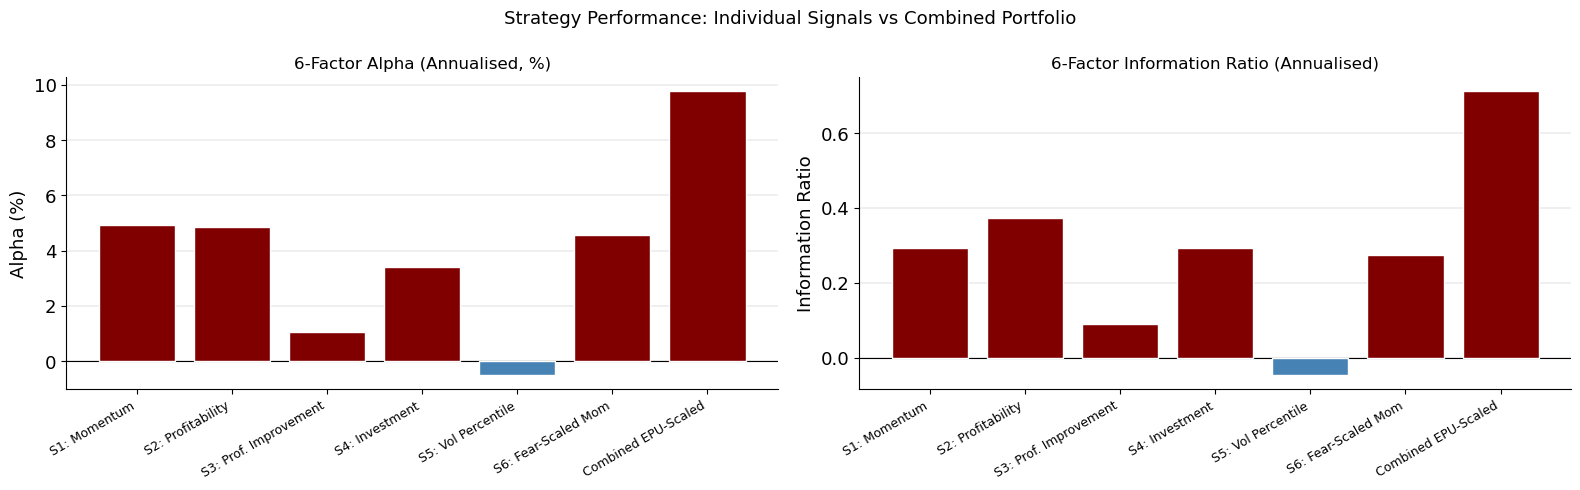

In [48]:
perf_labels = list(indiv_ir.keys()) + ['Combined EPU-Scaled']
alphas      = [indiv_ir[k]['Alpha (ann.)'] for k in indiv_ir.keys()] + [m5.params['const'] * 12 * 100]
irs         = [indiv_ir[k]['IR'] for k in indiv_ir.keys()] + [ir_df.loc['6FF-EPU', 'Info. Ratio']]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

colors_bar = ['maroon' if a > 0 else 'steelblue' for a in alphas]
ax1.bar(perf_labels, alphas, color=colors_bar, edgecolor='white', zorder=5)
ax1.axhline(0, color='black', lw=0.8)
ax1.set_title("6-Factor Alpha (Annualised, %)", fontsize=12)
ax1.set_ylabel("Alpha (%)")
ax1.set_xticklabels(perf_labels, rotation=30, ha='right', fontsize=9)

colors_ir = ['maroon' if ir > 0 else 'steelblue' for ir in irs]
ax2.bar(perf_labels, irs, color=colors_ir, edgecolor='white', zorder=5)
ax2.axhline(0, color='black', lw=0.8)
ax2.set_title("6-Factor Information Ratio (Annualised)", fontsize=12)
ax2.set_ylabel("Information Ratio")
ax2.set_xticklabels(perf_labels, rotation=30, ha='right', fontsize=9)

plt.suptitle("Strategy Performance: Individual Signals vs Combined Portfolio", fontsize=13)
plt.tight_layout()
plt.savefig('fig_perf_summary.png', dpi=120)
plt.show(); plt.close()

### 5.5 Monthly return distribution

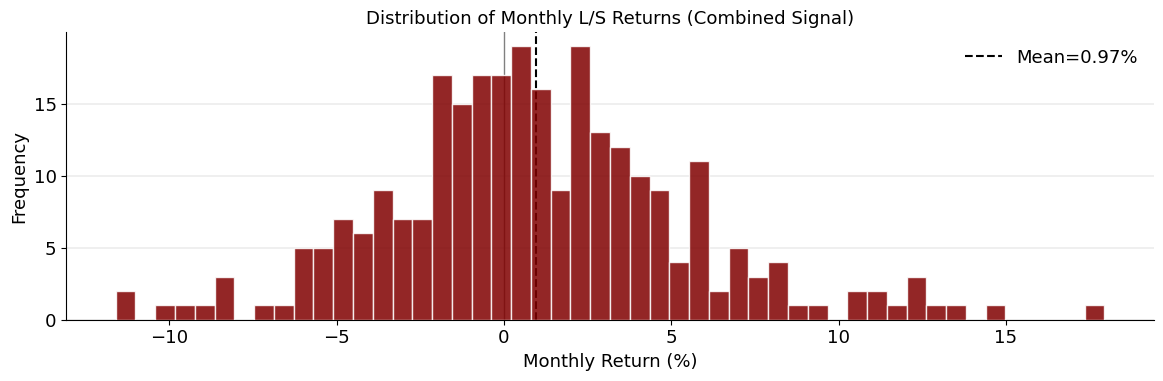

In [49]:
fig, ax = plt.subplots(figsize=(12, 4))
ls_clean = df_anal['LS'].dropna() * 100
ax.hist(ls_clean, bins=50, color='maroon', edgecolor='white', alpha=0.85, zorder=5)
ax.axvline(ls_clean.mean(), color='black', lw=1.5, linestyle='--', label=f'Mean={ls_clean.mean():.2f}%')
ax.axvline(0, color='gray', lw=1.0)
ax.set_title("Distribution of Monthly L/S Returns (Combined Signal)", fontsize=13)
ax.set_xlabel("Monthly Return (%)"); ax.set_ylabel("Frequency")
ax.legend()
plt.tight_layout()
plt.savefig('fig_ret_dist.png', dpi=120)
plt.show(); plt.close()

### Final print

In [50]:
print("\n" + "="*60)
print("ANALYSIS COMPLETE")
print("="*60)

def _sr(s): return s.mean()*12 / (s.std()*np.sqrt(12))

print(f"\n{'':45s}  {'EPU-Scaled':>12}  {'Unscaled':>10}")
print(f"  {'Annualised Return':45s}  {ls_ret.mean()*12*100:+10.2f}%  {ls_orig.mean()*12*100:+8.2f}%")
print(f"  {'Annualised Vol':45s}  {ls_ret.std()*np.sqrt(12)*100:10.2f}%  {ls_orig.std()*np.sqrt(12)*100:8.2f}%")
print(f"  {'Sharpe Ratio':45s}  {_sr(ls_ret):+10.3f}   {_sr(ls_orig):+8.3f}")
print(f"  {'Max Drawdown':45s}  {max_drawdown(ls_ret).min()*100:10.2f}%  {max_drawdown(ls_orig).min()*100:8.2f}%")
print(f"  {'Skewness':45s}  {ls_ret.skew():+10.3f}   {ls_orig.skew():+8.3f}")
print(f"  {'Kurtosis':45s}  {ls_ret.kurtosis():+10.3f}   {ls_orig.kurtosis():+8.3f}")
print(f"\n  {'6FF Alpha (ann.)':45s}  {m5.params['const']*12*100:+10.3f}%  {m5_orig.params['const']*12*100:+8.3f}%")
print(f"  {'6FF Alpha t-stat':45s}  {m5.tvalues['const']:+10.3f}   {m5_orig.tvalues['const']:+8.3f}")
print(f"  {'6FF Info. Ratio':45s}  {ir_df.loc['6FF-EPU','Info. Ratio']:+10.3f}   {ir_df.loc['6FF-Raw','Info. Ratio']:+8.3f}")
print(f"\n  EPU Regime Counts: High-EPU(×0.5)={n_hi}m  Normal(×1.0)={n_mid}m  Low-EPU(×2.0)={n_lo}m")


ANALYSIS COMPLETE

                                                 EPU-Scaled    Unscaled
  Annualised Return                                  +11.70%    +10.71%
  Annualised Vol                                      15.77%     15.99%
  Sharpe Ratio                                       +0.741     +0.670
  Max Drawdown                                       -29.71%    -48.10%
  Skewness                                           +0.390     +0.254
  Kurtosis                                           +1.047     +0.806

  6FF Alpha (ann.)                                   +9.778%    +9.039%
  6FF Alpha t-stat                                   +3.209     +2.992
  6FF Info. Ratio                                    +0.712     +0.664

  EPU Regime Counts: High-EPU(×0.5)=28m  Normal(×1.0)=216m  Low-EPU(×2.0)=28m
